# ACME Talent Insights Dashboard

**Audience:** HR leadership, people managers and the data team.
**Purpose:** answer ACME's seven performance and talent questions from trusted, validated data.

| Section | What you will find |
|---|---|
| [How to read this report](#how-to-read) | Plain-language guide to the terms and charts |
| [1. Can we trust the numbers?](#trust) | Pipeline run, data quality, and cross-checks of every Gold table |
| [2. Executive dashboard](#dashboard) | Headline metrics and a one-page overview |
| [Q1. Performance ratings and review history](#q1) | Ratings by period, department trends, history for any employee |
| [Q2. Critical skill gaps](#q2) | Who has critical gaps and in which competencies |
| [Q3. Ready for promotion](#q3) | 9-box talent grid, recommended candidates |
| [Q4. Training and development](#q4) | Activity over time, completions per employee |
| [Q5. Attrition risk](#q5) | Explainable risk score, who is at risk and why |
| [Q6. Performance vs team and project outcomes](#q6) | Team ratings against on-time delivery |
| [Q7. Skill distribution](#q7) | Proficiency levels across the organization |
| [3. Interactive explorer](#explorer) | Filter by department, look up any employee |
| [4. Summary and recommendations](#summary) | Answers in one table, recommended actions, limitations |
| [Appendix: SQL](#sql) | The same answers as SQL queries for pgAdmin |

**Data flow:** PostgreSQL HR tables and LMS event files → **Bronze** (raw copy) → **Silver** (validated) → **Gold** (one table per question) → this notebook. The notebook only **reads** data. It never changes it.

<a id="how-to-read"></a>
## How to read this report

| Term | Meaning |
|---|---|
| **Rating** | Performance review score from 1 (lowest) to 5 (highest). Two review periods: 2024-H2 and 2025-H1. |
| **Trend** | Latest rating compared with the previous one: improving, stable or declining. |
| **Proficiency / required level** | An employee's skill level (1–5) and the level their role requires. |
| **Skill gap** | Required level minus proficiency. **Critical** = 2 or more levels short, **moderate** = 1 level short. |
| **Potential / readiness** | HR's talent review: potential (Low/Medium/High) and promotion readiness (Ready Now / 1-2 Years / Not Ready). |
| **Risk score** | 0–100 attrition score built from HR's risk label, rating trend, low rating, learning inactivity and short tenure. **High ≥ 60, Medium ≥ 30.** |
| **r (correlation)** | How strongly two measures move together, from −1 to +1. Around 0.3 is weak, 0.5 is moderate, above 0.7 is strong. It does **not** prove cause and effect. |

**Chart titles state the finding**, so you can read the headline without studying the chart. Each question ends with **key findings** that are recomputed from the data on every run.

## Setup

**Data source** (environment variable `DASHBOARD_SOURCE`):
- `postgres` (default): reads the `gold`, `silver` and `quarantine` schemas that the pipeline publishes to PostgreSQL.
- `lake`: reads the same tables as Parquet files from the data lake (local folder or S3), e.g. on the cloud JupyterHub.

Connection settings use the same environment variables as the pipeline job.

In [1]:
import io
import json
import os
import warnings
from pathlib import Path

warnings.filterwarnings("ignore", category=SyntaxWarning)  # an old system package warns on import
warnings.filterwarnings("ignore", category=UserWarning)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import HTML, Markdown, display

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

IS_LOCAL = os.environ.get("IS_LOCAL", "true").lower() == "true"
SOURCE = os.environ.get("DASHBOARD_SOURCE", "postgres").lower()
BUCKET = os.environ.get("AWS_S3_BUCKET", "")
LAKE_ROOT = os.environ.get("LAKE_ROOT") or (str(Path.home() / "talent-etl-lake") if IS_LOCAL else f"s3://{BUCKET}/lake")
DB = {
    "host": os.environ.get("POSTGRES_HOST") or "localhost",
    "port": int(os.environ.get("POSTGRES_PORT") or 5432),
    "dbname": os.environ.get("POSTGRES_NAME") or "postgres",
    "user": os.environ.get("POSTGRES_USER") or "postgres",
    # Local workshop default only; set POSTGRES_PASS for any other database.
    "password": os.environ.get("POSTGRES_PASS") or ("postgres123" if IS_LOCAL else ""),
    "sslmode": "prefer" if IS_LOCAL else "require",
    "connect_timeout": 10,
}

conn = None
if SOURCE == "postgres":
    import psycopg
    conn = psycopg.connect(**DB, autocommit=True)


def query(sql: str, params: tuple | None = None) -> pd.DataFrame:
    """Run a read-only SQL query and return a DataFrame."""
    with conn.cursor() as cur:
        cur.execute(sql, params)
        return pd.DataFrame(cur.fetchall(), columns=[d.name for d in cur.description])


def lake_files(prefix: str) -> list[tuple[str, bytes]]:
    """(key, bytes) for every file under a lake prefix, local or S3."""
    if LAKE_ROOT.startswith("s3://"):
        import boto3
        bucket, _, root = LAKE_ROOT[5:].partition("/")
        s3 = boto3.client("s3")
        keys = [o["Key"] for page in s3.get_paginator("list_objects_v2").paginate(
            Bucket=bucket, Prefix=f"{root}/{prefix}/".lstrip("/")) for o in page.get("Contents", [])]
        return [(k, s3.get_object(Bucket=bucket, Key=k)["Body"].read()) for k in sorted(keys)]
    base = Path(LAKE_ROOT) / prefix
    return [(str(p), p.read_bytes()) for p in sorted(base.rglob("*")) if p.is_file()] if base.exists() else []


def normalize(df: pd.DataFrame) -> pd.DataFrame:
    """Give both sources the same plain dtypes: dates as datetime64, numbers as numbers, text as object."""
    for col in df.columns:
        s = df[col]
        if isinstance(s.dtype, pd.CategoricalDtype):
            df[col] = s.astype(object)
        elif pd.api.types.is_extension_array_dtype(s.dtype):  # Arrow / nullable types from Parquet
            if pd.api.types.is_bool_dtype(s.dtype):
                df[col] = s.astype(bool) if not s.isna().any() else s.astype(object)
            elif pd.api.types.is_integer_dtype(s.dtype):
                df[col] = s.astype("int64") if not s.isna().any() else s.astype("float64")
            elif pd.api.types.is_float_dtype(s.dtype):
                df[col] = s.astype("float64")
            elif pd.api.types.is_datetime64_any_dtype(s.dtype):
                df[col] = pd.to_datetime(s).astype("datetime64[ns]")
            else:
                df[col] = s.astype(object).where(s.notna(), None)
    for col in df.columns:
        if df[col].dtype == object:
            sample = df[col].dropna()
            if sample.empty:
                continue
            first = sample.iloc[0]
            if hasattr(first, "year") and hasattr(first, "month"):
                df[col] = pd.to_datetime(df[col])
            elif isinstance(first, (int, float, np.number)) and not isinstance(first, bool):
                df[col] = pd.to_numeric(df[col])
    return df


def load(schema: str, table: str) -> pd.DataFrame:
    """Load a published table from PostgreSQL, or its Parquet files from the lake."""
    if SOURCE == "postgres":
        return normalize(query(f'SELECT * FROM "{schema}"."{table}"'))
    files = [data for key, data in lake_files(f"{schema}/{table}") if key.endswith(".parquet")]
    return normalize(pd.concat([pd.read_parquet(io.BytesIO(d)) for d in files], ignore_index=True)) if files else pd.DataFrame()


# Chart style
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 10.5, "font.size": 9,
                     "axes.titlelocation": "left"})
BLUE, GREEN, AMBER, RED, GREY, PURPLE = "#2563eb", "#16a34a", "#f59e0b", "#dc2626", "#9ca3af", "#7c3aed"
RISK_COLORS = {"High": RED, "Medium": AMBER, "Low": GREEN}


def label_bars(ax, fmt="{:,.0f}"):
    """Write each bar's value next to the bar."""
    for container in ax.containers:
        ax.bar_label(container, labels=[fmt.format(v) for v in container.datavalues], padding=2, fontsize=8)


def top_counts(series: pd.Series, n: int) -> pd.Series:
    """Most frequent values; ties broken alphabetically so the order is stable."""
    return series.value_counts().sort_index().sort_values(ascending=False, kind="stable").head(n)


def heatmap(ax, frame: pd.DataFrame, fmt="{:.0f}", cmap="Reds"):
    """Annotated heatmap with readable text on dark cells."""
    values = frame.values.astype(float)
    low, high = np.nanmin(values), np.nanmax(values)
    ax.imshow(values, cmap=cmap, aspect="auto")
    ax.set_xticks(range(frame.shape[1]), frame.columns)
    ax.set_yticks(range(frame.shape[0]), frame.index)
    for i in range(frame.shape[0]):
        for j in range(frame.shape[1]):
            v = values[i, j]
            ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=8,
                    color="white" if high > low and (v - low) / (high - low) > 0.6 else "black")
    ax.spines[:].set_visible(False)


def kpi_cards(items):
    """Render KPI cards: (title, value, subtitle, colour)."""
    cards = "".join(
        f'''<div style="border-left:5px solid {c};background:#f8fafc;padding:10px 14px;border-radius:6px">
             <div style="font-size:12px;color:#475569">{t}</div>
             <div style="font-size:26px;font-weight:700;color:#0f172a">{v}</div>
             <div style="font-size:11px;color:#64748b">{s}</div></div>''' for t, v, s, c in items)
    display(HTML(f'<div style="display:grid;grid-template-columns:repeat(auto-fit,minmax(170px,1fr));gap:10px">{cards}</div>'))


where = f"PostgreSQL {DB['user']}@{DB['host']}:{DB['port']}/{DB['dbname']}" if SOURCE == "postgres" else f"lake {LAKE_ROOT}"
print(f"Data source: {where}")

Data source: PostgreSQL postgres@localhost:5432/postgres


In [2]:
# Load every table the report uses.
GOLD = ["employee_performance_history", "employee_skill_gaps", "promotion_candidates", "employee_learning_summary",
        "attrition_risk", "team_performance_outcomes", "team_outcome_correlation", "skill_distribution"]
SILVER = ["dim_employee", "fact_performance_review", "fact_competency_assessment", "fact_talent_review",
          "fact_learning_event", "fact_project"]
gold = {t: load("gold", t) for t in GOLD}
silver = {t: load("silver", t) for t in SILVER}
quarantine = {t: load("quarantine", t) for t in ["learning_activity", "learning_activity_duplicates"]}

missing = [f"gold.{t}" for t, df in gold.items() if df.empty] + [f"silver.{t}" for t, df in silver.items() if df.empty]
assert not missing, f"Missing tables {missing}: run the pipeline first (python3 job.py)."

history, gaps, promo = gold["employee_performance_history"], gold["employee_skill_gaps"], gold["promotion_candidates"]
learning, risk, teams = gold["employee_learning_summary"], gold["attrition_risk"], gold["team_performance_outcomes"]
corr, skills = gold["team_outcome_correlation"], gold["skill_distribution"]
events, projects = silver["fact_learning_event"], silver["fact_project"]

pd.DataFrame([(f"{layer}.{t}", len(df)) for layer, tables in [("gold", gold), ("silver", silver), ("quarantine", quarantine)]
              for t, df in tables.items()], columns=["table", "rows"])

,table,rows
0,gold.employee_performance_history,4000
1,gold.employee_skill_gaps,4000
2,gold.promotion_candidates,357
3,gold.employee_learning_summary,2000
4,gold.attrition_risk,2000
5,gold.team_performance_outcomes,100
6,gold.team_outcome_correlation,6
7,gold.skill_distribution,1595
8,silver.dim_employee,2000
9,silver.fact_performance_review,4000


<a id="trust"></a>
---
# 1. Can we trust the numbers?

Before any insight, three checks: **which pipeline run** produced the data and whether it passed its reconciliation checks, **what bad data was excluded**, and an **independent cross-check** of every Gold table against Silver.

In [3]:
run_ids = sorted(set(pd.concat([df["_run_id"] for df in gold.values() if "_run_id" in df]).dropna()))
gold_run = run_ids[-1]


def read_manifest(run_id: str) -> dict | None:
    """Run manifest from the lake (_meta/runs/<run_id>.json), if the lake is reachable from here."""
    try:
        files = dict(lake_files("_meta/runs"))
    except Exception:  # noqa: BLE001 - the manifest is optional context
        return None
    match = [data for key, data in files.items() if key.endswith(f"{run_id}.json")]
    return json.loads(match[0]) if match else None


manifest = read_manifest(gold_run)
if manifest:
    checks = pd.DataFrame(manifest["checks"])
    stages = pd.DataFrame(manifest["stages"]).T[["duration_s", "records", "records_per_min", "peak_rss_mb"]]
    kpi_cards([
        ("Gold built by run", gold_run.split("-")[0][:15], gold_run, BLUE),
        ("Run status", manifest["status"], f"{manifest['duration_s']} s end to end", GREEN if manifest["status"] == "SUCCESS" else RED),
        ("Reconciliation checks", f"{int(checks['passed'].sum())}/{len(checks)}", "rows in = rows out + rejected", GREEN if checks["passed"].all() else RED),
        ("As-of date", manifest["config"]["as_of_date"], "'today' for tenure and recency", GREY),
    ])
    display(Markdown("**Pipeline stages of that run:**"))
    display(stages)
    failed = checks[~checks["passed"]]
    display(Markdown("All reconciliation checks passed." if failed.empty else "**Failed checks:**"))
    if not failed.empty:
        display(failed)
else:
    display(Markdown(f"Gold built by run `{gold_run}`. The run manifest is not reachable from this environment, so its checks are not shown."))

**Pipeline stages of that run:**

,duration_s,records,records_per_min,peak_rss_mb
bronze,0.81,12173,901704,142.0
silver,3.27,42041,771394,290.9
gold,0.34,14058,2480824,290.9
serve,0.9,56099,3739933,290.9


All reconciliation checks passed.

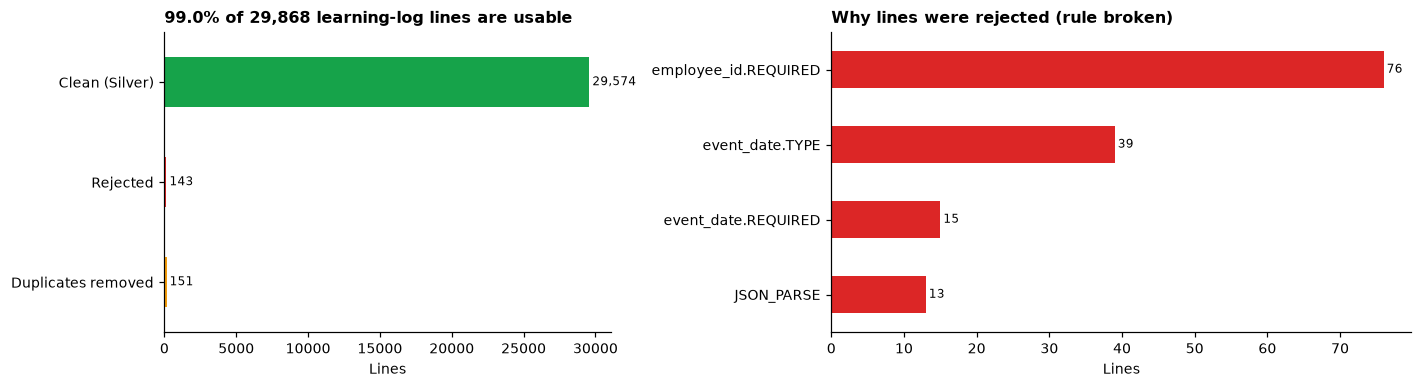

Rejected lines are **kept in quarantine with the reason, file and line number**, not deleted. No HR database rows were rejected. In the HR data, **334 reviews** are dated before the employee's hire date. They are kept and flagged (`dq_review_before_hire`).

In [4]:
lines_total = len(events) + len(quarantine["learning_activity"]) + len(quarantine["learning_activity_duplicates"])
rules = (quarantine["learning_activity"]["_rule_id"].str.replace("learning_activity.", "", regex=False).value_counts()
         if not quarantine["learning_activity"].empty else pd.Series(dtype=int))

fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), gridspec_kw={"width_ratios": [1, 1.3]})
outcome = pd.Series({"Clean (Silver)": len(events), "Rejected": len(quarantine["learning_activity"]),
                     "Duplicates removed": len(quarantine["learning_activity_duplicates"])})
outcome.plot.barh(ax=axes[0], color=[GREEN, RED, AMBER])
axes[0].invert_yaxis()
axes[0].set(title=f"{outcome.iloc[0] / lines_total:.1%} of {lines_total:,} learning-log lines are usable", xlabel="Lines")
label_bars(axes[0])
rules.sort_values().plot.barh(ax=axes[1], color=RED)
axes[1].set(title="Why lines were rejected (rule broken)", xlabel="Lines", ylabel="")
label_bars(axes[1])
plt.tight_layout()
plt.show()
display(Markdown(
    f"Rejected lines are **kept in quarantine with the reason, file and line number**, not deleted. "
    f"No HR database rows were rejected. In the HR data, **{int(history['dq_review_before_hire'].sum())} reviews** "
    f"are dated before the employee's hire date. They are kept and flagged (`dq_review_before_hire`)."))

**Independent cross-check of Gold against Silver.** Each Gold table is re-derived or counted from the Silver tables here in the notebook, and compared with what the pipeline produced. This includes **recomputing every employee's attrition risk score** from its inputs.

In [5]:
def risk_components(df: pd.DataFrame) -> pd.DataFrame:
    """Points per signal, using the documented attrition-risk weights."""
    no_learning = df["days_since_last_learning"].isna() | (df["days_since_last_learning"] > 180)
    return pd.DataFrame({
        "HR risk label": df["hr_attrition_risk"].map({"High": 40, "Medium": 20, "Low": 0}).fillna(0),
        "Rating drop": np.select([df["rating_delta"] <= -2, df["rating_delta"] == -1], [25, 15], 0),
        "Low rating (≤2)": np.where(df["latest_rating"] <= 2, 15, 0),
        "No learning 180d": np.where(no_learning, 10, 0),
        "Tenure < 1 year": np.where(df["tenure_years"] < 1, 10, 0),
    }, index=df.index)


talent = silver["fact_talent_review"]
recomputed_score = risk_components(risk).sum(axis=1).clip(0, 100)
cross_checks = [
    ("Performance history rows = Silver reviews", len(history), len(silver["fact_performance_review"])),
    ("Skill-gap rows = Silver assessments", len(gaps), len(silver["fact_competency_assessment"])),
    ("Attrition rows = employees (one per employee)", risk["employee_id"].nunique(), len(silver["dim_employee"])),
    ("Learning summary rows = employees", len(learning), len(silver["dim_employee"])),
    ("Learning events counted = Silver events", int(learning["total_events"].sum()), len(events)),
    ("Promotion candidates = High potential & Ready Now", len(promo),
     int(((talent["potential_rating"] == "High") & (talent["promotion_readiness"] == "Ready Now")).sum())),
    ("Projects counted in team outcomes = Silver projects", int(teams["project_count"].sum()), len(projects)),
    ("Skill distribution total = assessments", int(skills["employee_count"].sum()), len(gaps)),
    ("Critical gaps = assessments with gap ≥ 2", int((gaps["gap_severity"] == "critical").sum()),
     int(((silver["fact_competency_assessment"]["required_level"]
           - silver["fact_competency_assessment"]["proficiency_level"]) >= 2).sum())),
    ("Risk scores recomputed in notebook = pipeline", int((recomputed_score == risk["computed_risk_score"]).sum()), len(risk)),
]
cross = pd.DataFrame(cross_checks, columns=["check", "gold", "expected"])
cross["result"] = np.where(cross["gold"] == cross["expected"], "✓ pass", "✗ FAIL")
display(cross)
assert (cross["gold"] == cross["expected"]).all(), "A Gold cross-check failed"
display(Markdown(f"**All {len(cross)} cross-checks pass.** The numbers below are consistent with the validated Silver data."))

,check,gold,expected,result
0,Performance history rows = Silver reviews,4000,4000,✓ pass
1,Skill-gap rows = Silver assessments,4000,4000,✓ pass
2,Attrition rows = employees (one per employee),2000,2000,✓ pass
3,Learning summary rows = employees,2000,2000,✓ pass
4,Learning events counted = Silver events,29574,29574,✓ pass
5,Promotion candidates = High potential & Ready Now,357,357,✓ pass
6,Projects counted in team outcomes = Silver pro...,33,33,✓ pass
7,Skill distribution total = assessments,4000,4000,✓ pass
8,Critical gaps = assessments with gap ≥ 2,325,325,✓ pass
9,Risk scores recomputed in notebook = pipeline,2000,2000,✓ pass


**All 10 cross-checks pass.** The numbers below are consistent with the validated Silver data.

<a id="dashboard"></a>
---
# 2. Executive dashboard

In [6]:
periods = sorted(history["review_period"].unique())
first_p, latest_p = periods[0], periods[-1]
avg_by_period = history.groupby("review_period")["rating"].mean()
critical = gaps[gaps["gap_severity"] == "critical"]
rec = promo[promo["is_recommended"]]
hp_at_risk = risk[(risk["risk_band"] == "High") & (risk["potential_rating"] == "High")]

kpi_cards([
    ("Employees", f"{risk['employee_id'].nunique():,}", f"{risk['team_id'].nunique()} teams · {risk['department'].nunique()} departments", BLUE),
    ("Average rating", f"{avg_by_period[latest_p]:.2f}", f"{latest_p} (was {avg_by_period[first_p]:.2f} in {first_p})", BLUE),
    ("Declining performers", f"{(risk['rating_trend'] == 'declining').sum():,}", "rating fell since last review", AMBER),
    ("Critical skill gaps", f"{critical['employee_id'].nunique():,}", f"employees ({len(critical):,} gaps)", RED),
    ("Ready for promotion", f"{len(rec):,}", f"recommended of {len(promo):,} HR candidates", GREEN),
    ("High attrition risk", f"{(risk['risk_band'] == 'High').sum():,}", f"{len(hp_at_risk)} of them high-potential", RED),
    ("Courses completed", f"{int(learning['course_completed_count'].sum()):,}",
     f"{(learning['course_completed_count'] > 0).mean():.0%} of employees completed one", GREEN),
    ("Skills below required", f"{(gaps['gap'] > 0).mean():.0%}", "of all skill assessments", AMBER),
])

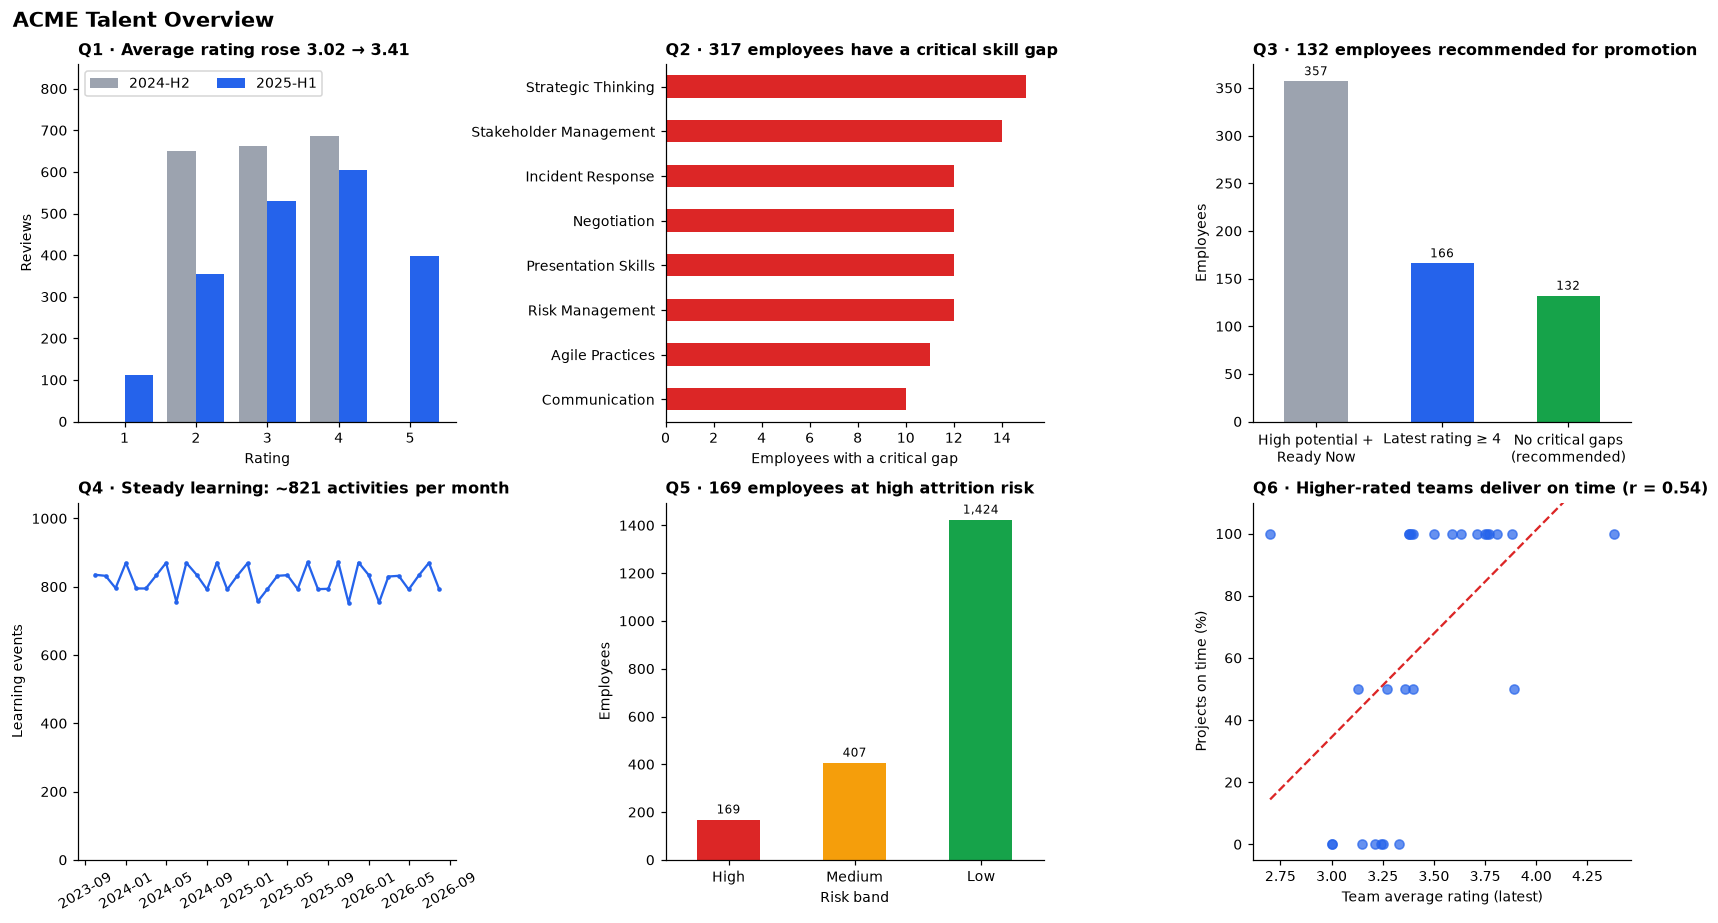

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8.5))
fig.suptitle("ACME Talent Overview", fontsize=14, fontweight="bold", x=0.01, ha="left")

# Q1: ratings by period
dist = history.pivot_table(index="rating", columns="review_period", values="employee_id", aggfunc="count").fillna(0)
dist.index = dist.index.astype(int)
dist.plot.bar(ax=axes[0, 0], color=[GREY, BLUE], rot=0, width=0.8)
axes[0, 0].set(title=f"Q1 · Average rating rose {avg_by_period[first_p]:.2f} → {avg_by_period[latest_p]:.2f}",
               xlabel="Rating", ylabel="Reviews", ylim=(0, dist.values.max() * 1.25))
axes[0, 0].legend(title=None, ncol=2, loc="upper left")

# Q2: critical gaps
top_counts(critical["competency_name"], 8).iloc[::-1].plot.barh(ax=axes[0, 1], color=RED)
axes[0, 1].set(title=f"Q2 · {critical['employee_id'].nunique()} employees have a critical skill gap",
               xlabel="Employees with a critical gap", ylabel="")

# Q3: promotion funnel
funnel = pd.Series({"High potential +\nReady Now": len(promo), "Latest rating ≥ 4": int((promo["latest_rating"] >= 4).sum()),
                    "No critical gaps\n(recommended)": len(rec)})
funnel.plot.bar(ax=axes[0, 2], color=[GREY, BLUE, GREEN], rot=0)
axes[0, 2].set(title=f"Q3 · {len(rec)} employees recommended for promotion", ylabel="Employees")
label_bars(axes[0, 2])

# Q4: learning over time (line)
monthly = events.set_index("event_ts").resample("MS")["event_id"].count()
monthly = monthly.iloc[1:-1]  # drop partial first/last months
axes[1, 0].plot(monthly.index, monthly.values, color=BLUE, marker="o", markersize=2)
axes[1, 0].set(title=f"Q4 · Steady learning: ~{monthly.mean():,.0f} activities per month", ylabel="Learning events",
               ylim=(0, monthly.max() * 1.2))
axes[1, 0].tick_params(axis="x", rotation=30)

# Q5: risk bands
bands = risk["risk_band"].value_counts().reindex(["High", "Medium", "Low"])
bands.plot.bar(ax=axes[1, 1], color=[RISK_COLORS[b] for b in bands.index], rot=0)
axes[1, 1].set(title=f"Q5 · {bands['High']} employees at high attrition risk", ylabel="Employees", xlabel="Risk band")
label_bars(axes[1, 1])

# Q6: team rating vs on-time
with_projects = teams[teams["project_count"] > 0]
r_on_time = corr.query("metric_x == 'avg_rating_latest' and metric_y == 'on_time_pct'")["pearson_r"].iloc[0]
axes[1, 2].scatter(with_projects["avg_rating_latest"], with_projects["on_time_pct"], color=BLUE, alpha=0.7)
m, b = np.polyfit(with_projects["avg_rating_latest"], with_projects["on_time_pct"], 1)
xs = np.linspace(with_projects["avg_rating_latest"].min(), with_projects["avg_rating_latest"].max(), 10)
axes[1, 2].plot(xs, m * xs + b, color=RED, linestyle="--")
axes[1, 2].set(title=f"Q6 · Higher-rated teams deliver on time (r = {r_on_time:.2f})",
               xlabel="Team average rating (latest)", ylabel="Projects on time (%)", ylim=(-5, 110))
plt.tight_layout()
plt.show()

<a id="q1"></a>
---
# Q1. What are the performance ratings and review history for each employee?

**How it is measured:** `gold.employee_performance_history` holds one row per employee per review period, with the previous rating and the change. The trend compares each employee's latest rating with the previous one.

### Answer: every employee has 2 reviews. The average rose from **3.02 to 3.41**, and **230** employees declined.

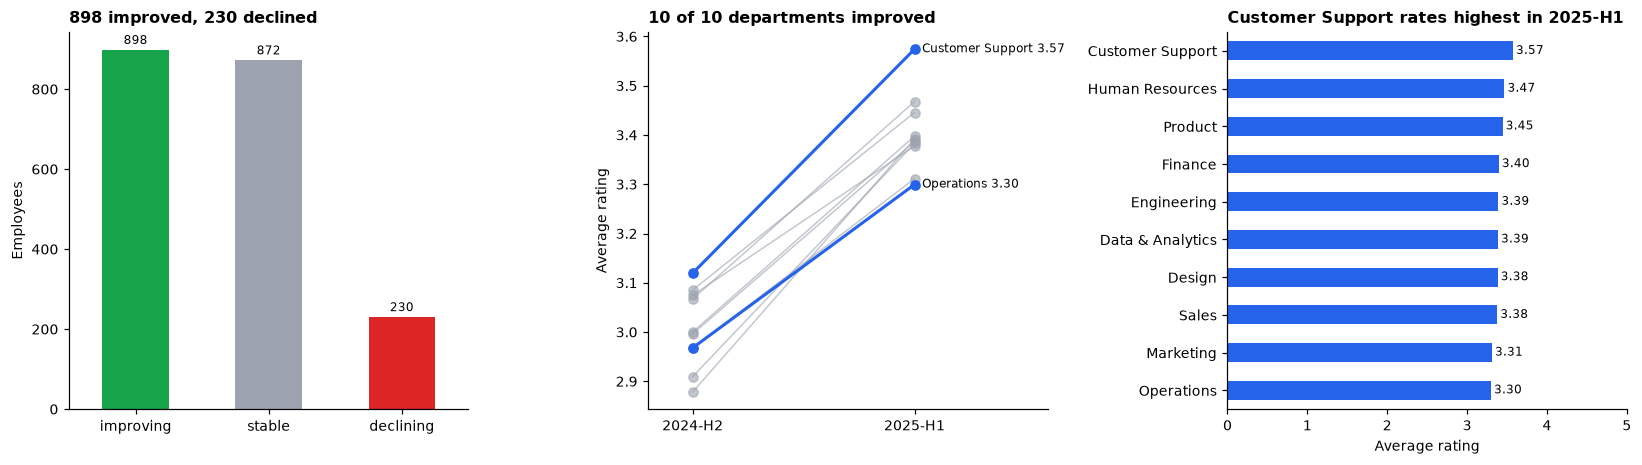

**Number of reviews per rating:**

rating,1.0,2.0,3.0,4.0,5.0
review_period,,,,,
2024-H2,0,650,663,687,0
2025-H1,112,354,530,605,399


In [8]:
trend = risk["rating_trend"].value_counts().reindex(["improving", "stable", "declining"]).fillna(0)
dept_period = history.pivot_table(index="department", columns="review_period", values="rating", aggfunc="mean")
dept_latest = dept_period[latest_p].sort_values()
display(Markdown(f"### Answer: every employee has {history.groupby('employee_id').size().mode()[0]} reviews. The average rose from "
                 f"**{avg_by_period[first_p]:.2f} to {avg_by_period[latest_p]:.2f}**, and **{int(trend['declining'])}** employees declined."))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
trend.plot.bar(ax=axes[0], color=[GREEN, GREY, RED], rot=0)
axes[0].set(title=f"{int(trend['improving'])} improved, {int(trend['declining'])} declined", ylabel="Employees", xlabel="")
label_bars(axes[0])

# Line (slope) chart: every department improved between the two periods
for dept, row in dept_period.iterrows():
    highlight = dept in (dept_latest.index[0], dept_latest.index[-1])
    axes[1].plot(periods, row[periods].values, marker="o", color=BLUE if highlight else GREY,
                 linewidth=2 if highlight else 1, alpha=1 if highlight else 0.6)
    if highlight:
        axes[1].annotate(f"{dept} {row[latest_p]:.2f}", (1, row[latest_p]), xytext=(5, 0),
                         textcoords="offset points", va="center", fontsize=8)
improved = int((dept_period[latest_p] > dept_period[first_p]).sum())
axes[1].set(title=f"{improved} of {len(dept_period)} departments improved", ylabel="Average rating", xlim=(-0.2, 1.6))

dept_latest.plot.barh(ax=axes[2], color=BLUE)
axes[2].set(title=f"{dept_latest.index[-1]} rates highest in {latest_p}", xlabel="Average rating", ylabel="", xlim=(0, 5))
label_bars(axes[2], "{:.2f}")
plt.tight_layout()
plt.show()

by_period = history.pivot_table(index="rating", columns="review_period", values="employee_id", aggfunc="count").fillna(0).astype(int)
by_period.index.name = "rating"
display(Markdown("**Number of reviews per rating:**"))
display(by_period.T)

In [9]:
# Review history for any employee: change EMPLOYEE_ID (or use the interactive explorer in section 3).
EMPLOYEE_ID = 702
history.loc[history["employee_id"] == EMPLOYEE_ID,
            ["employee_id", "full_name", "department", "job_level", "review_period", "rating", "prev_rating",
             "rating_delta", "manager_comment", "submitted_date"]].sort_values("review_period")

,employee_id,full_name,department,job_level,review_period,rating,prev_rating,rating_delta,manager_comment,submitted_date
1402,702,Crystal Logan,Marketing,Director,2024-H2,3.0,NaN,NaN,"Solid, consistent contributor this cycle.",2025-08-29
1403,702,Crystal Logan,Marketing,Director,2025-H1,1.0,3.0,-2.0,Struggled to meet deadlines; follow-up plan re...,2026-02-26


In [10]:
unused_first = " or ".join(str(r) for r in sorted(set(range(1, 6)) - set(history.loc[history["review_period"] == first_p, "rating"])))
display(Markdown(f"""
**Key findings**
- **{int(trend['improving']):,}** employees improved, **{int(trend['stable']):,}** were stable and **{int(trend['declining']):,}** declined.
- All {improved} departments improved. **{dept_latest.index[-1]}** is highest ({dept_latest.iloc[-1]:.2f}) and **{dept_latest.index[0]}** lowest ({dept_latest.iloc[0]:.2f}).
- {first_p} had **no ratings of {unused_first}**. Part of the rise may reflect how managers used the scale, not only real change, so it is worth a calibration review.
- Data quality: **{int(history['dq_review_before_hire'].sum())}** reviews are dated before the hire date. They are flagged, not deleted.
"""))


**Key findings**
- **898** employees improved, **872** were stable and **230** declined.
- All 10 departments improved. **Customer Support** is highest (3.57) and **Operations** lowest (3.30).
- 2024-H2 had **no ratings of 1 or 5**. Part of the rise may reflect how managers used the scale, not only real change, so it is worth a calibration review.
- Data quality: **334** reviews are dated before the hire date. They are flagged, not deleted.


<a id="q2"></a>
---
# Q2. Which employees have critical skill gaps in key competencies?

**How it is measured:** gap = required level − proficiency level (`gold.employee_skill_gaps`). **Critical** means the employee is **2 or more levels below** what the role requires. "Key competencies" are the ones with the most critical gaps.

### Answer: **317 employees** have **325 critical gaps**. The most affected competencies are **Strategic Thinking**, **Stakeholder Management** and **Incident Response**.

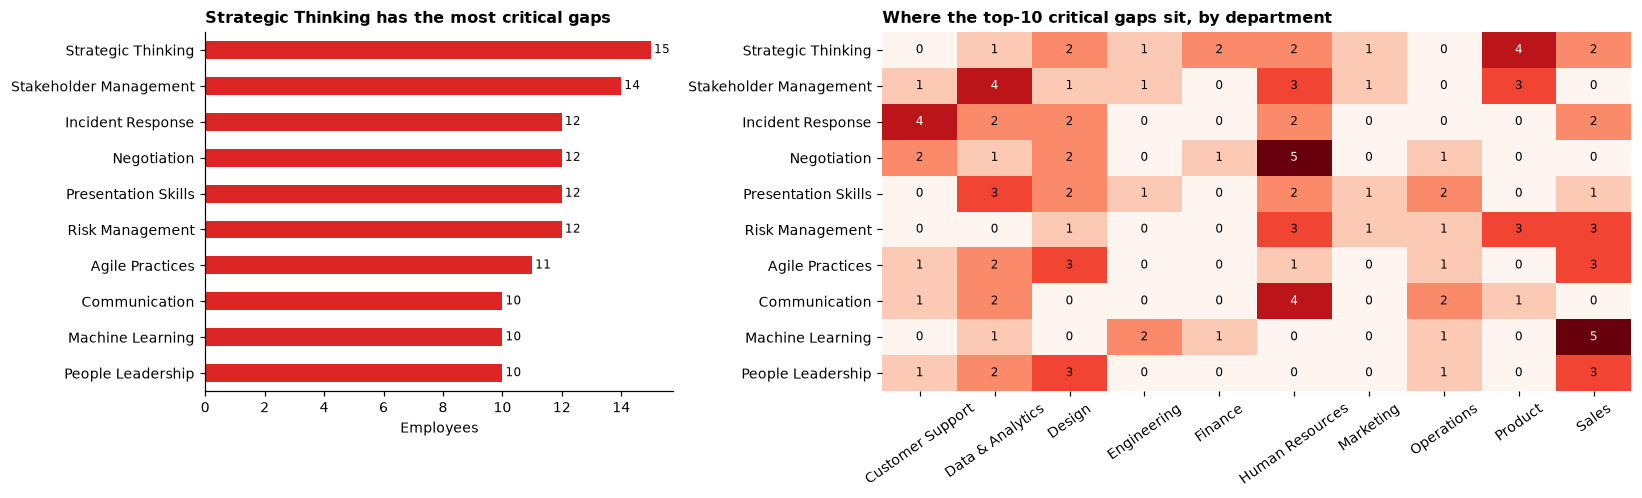

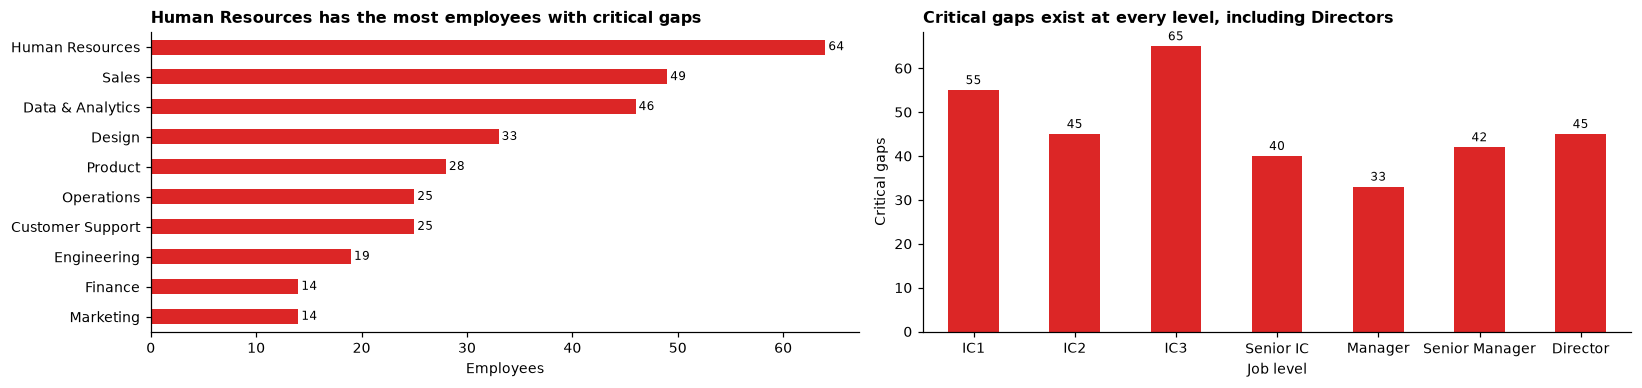

In [11]:
top10 = top_counts(critical["competency_name"], 10)
display(Markdown(f"### Answer: **{critical['employee_id'].nunique()} employees** have **{len(critical)} critical gaps**. The most affected "
                 f"competencies are **{top10.index[0]}**, **{top10.index[1]}** and **{top10.index[2]}**."))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6), gridspec_kw={"width_ratios": [1, 1.6]})
top10.iloc[::-1].plot.barh(ax=axes[0], color=RED)
axes[0].set(title=f"{top10.index[0]} has the most critical gaps", xlabel="Employees", ylabel="")
label_bars(axes[0])

grid = (critical[critical["competency_name"].isin(top10.index)]
        .pivot_table(index="competency_name", columns="department", values="employee_id", aggfunc="count")
        .reindex(top10.index).fillna(0))
heatmap(axes[1], grid)
axes[1].set_title("Where the top-10 critical gaps sit, by department")
axes[1].tick_params(axis="x", rotation=35)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15, 3.6))
crit_by_dept = critical.groupby("department")["employee_id"].nunique().sort_values()
crit_by_dept.plot.barh(ax=axes[0], color=RED)
axes[0].set(title=f"{crit_by_dept.index[-1]} has the most employees with critical gaps", xlabel="Employees", ylabel="")
label_bars(axes[0])
level_order = ["IC1", "IC2", "IC3", "Senior IC", "Manager", "Senior Manager", "Director"]
critical["job_level"].value_counts().reindex(level_order).fillna(0).plot.bar(ax=axes[1], color=RED, rot=0)
axes[1].set(title="Critical gaps exist at every level, including Directors", ylabel="Critical gaps", xlabel="Job level")
label_bars(axes[1])
plt.tight_layout()
plt.show()

In [12]:
# Every critical gap (first 15 of the full list).
critical_list = critical[["employee_id", "full_name", "department", "job_level", "competency_name", "category",
                          "proficiency_level", "required_level", "gap"]].sort_values(["department", "employee_id"])
print(f"{len(critical_list):,} critical gaps across {critical_list['employee_id'].nunique():,} employees")
critical_list.head(15)

325 critical gaps across 317 employees


,employee_id,full_name,department,job_level,competency_name,category,proficiency_level,required_level,gap
164,83,Rebecca Andrade,Customer Support,IC2,Python,Technical,1,3,2
182,92,Candace Johnson,Customer Support,Senior IC,API Design,Technical,1,3,2
186,94,Richard Tapia,Customer Support,Senior IC,Systems Design,Technical,1,3,2
194,98,Alexandra Soto,Customer Support,Senior IC,Incident Response,Technical,1,3,2
201,101,Amanda Jackson,Customer Support,Senior Manager,Technical Writing,Domain,2,4,2
462,232,Joseph Ferrell,Customer Support,IC3,Time Management,Domain,2,4,2
487,244,Manuel Wright,Customer Support,Manager,Data Privacy,Domain,1,3,2
1138,570,Jessica Novak,Customer Support,Senior Manager,Incident Response,Technical,1,3,2
1153,577,Kathleen Beasley,Customer Support,IC2,Test Automation,Technical,1,3,2
1175,588,Kelly Henderson,Customer Support,Director,Vendor Management,Domain,2,4,2


In [13]:
cat = critical["category"].value_counts()
by_level = critical["job_level"].value_counts()
dept_crit = critical.groupby("department")["employee_id"].nunique().sort_values(ascending=False)
display(Markdown(f"""
**Key findings**
- **{critical['employee_id'].nunique()}** employees have **{len(critical)}** critical gaps; **{int((critical.groupby('employee_id').size() > 1).sum())}** have more than one.
- By category: {", ".join(f"**{k}** {v}" for k, v in cat.items())}. Leadership has fewer gaps in total but the top single gap (**{top10.index[0]}**).
- Most affected departments: **{dept_crit.index[0]}** ({dept_crit.iloc[0]}) and **{dept_crit.index[1]}** ({dept_crit.iloc[1]}).
- Not only a junior issue: **Director** level has **{by_level.get('Director', 0)}** critical gaps.
"""))


**Key findings**
- **317** employees have **325** critical gaps; **8** have more than one.
- By category: **Domain** 172, **Technical** 103, **Leadership** 50. Leadership has fewer gaps in total but the top single gap (**Strategic Thinking**).
- Most affected departments: **Human Resources** (64) and **Sales** (49).
- Not only a junior issue: **Director** level has **45** critical gaps.


<a id="q3"></a>
---
# Q3. Who are the high-potential employees ready for promotion?

**How it is measured:** HR's talent review marks employees as **High potential** and **Ready Now**. We **recommend** them when the performance data agrees: a **latest rating of 4 or more** and **no critical skill gap**.

The **9-box grid** places every employee by performance (latest rating) and potential (HR talent review). It is the standard HR view for succession and promotion planning.

### Answer: **132 employees** are recommended for promotion, out of **357** that HR marked High potential and Ready Now.

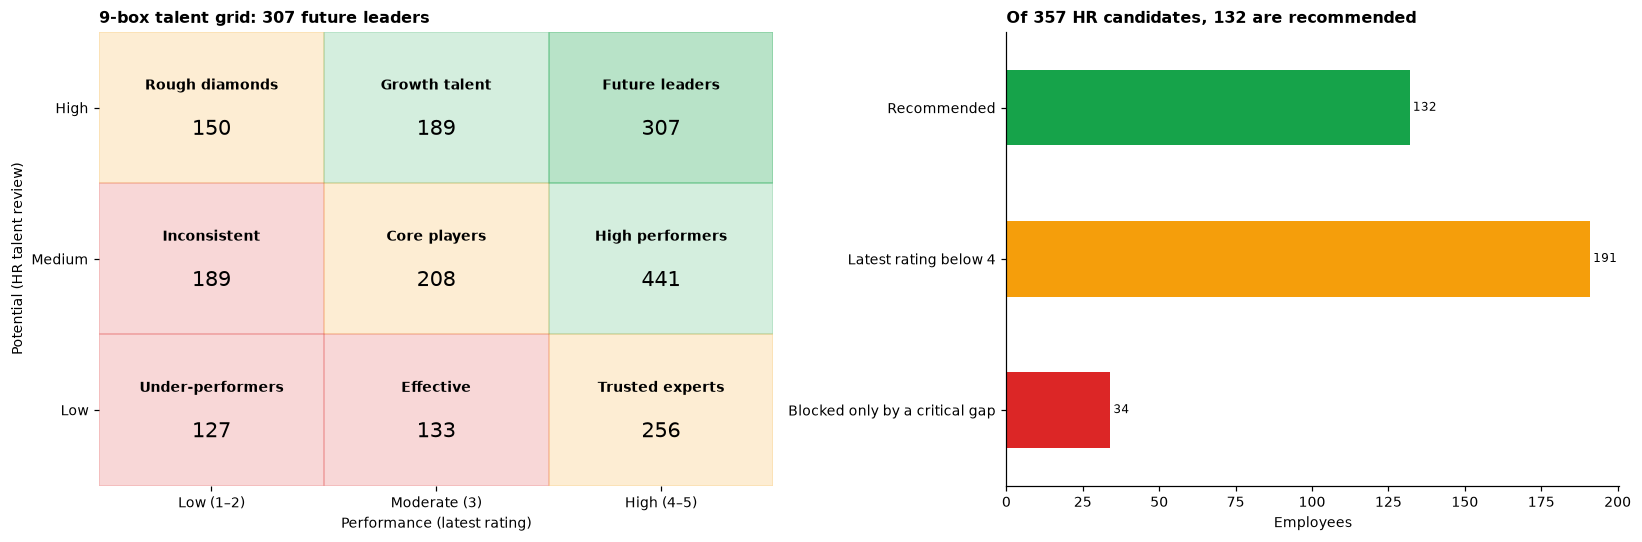

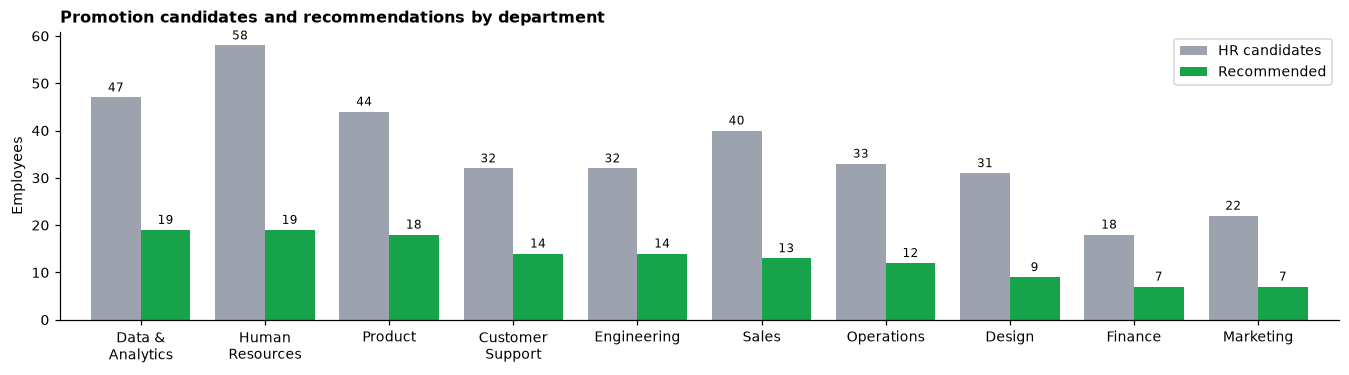

In [14]:
display(Markdown(f"### Answer: **{len(rec)} employees** are recommended for promotion, out of **{len(promo)}** that HR marked High potential and Ready Now."))

perf_tier = pd.cut(risk["latest_rating"], [0, 2, 3, 5], labels=["Low (1–2)", "Moderate (3)", "High (4–5)"])
nine = pd.crosstab(risk["potential_rating"], perf_tier).reindex(index=["High", "Medium", "Low"]).fillna(0)
names = {("High", "High (4–5)"): "Future leaders", ("High", "Moderate (3)"): "Growth talent",
         ("High", "Low (1–2)"): "Rough diamonds", ("Medium", "High (4–5)"): "High performers",
         ("Medium", "Moderate (3)"): "Core players", ("Medium", "Low (1–2)"): "Inconsistent",
         ("Low", "High (4–5)"): "Trusted experts", ("Low", "Moderate (3)"): "Effective",
         ("Low", "Low (1–2)"): "Under-performers"}

fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1.1, 1]})
ax = axes[0]
colors = np.array([[GREEN, GREEN, AMBER], [GREEN, AMBER, RED], [AMBER, RED, RED]])[:, ::-1]
for i, pot in enumerate(nine.index):
    for j, perf in enumerate(nine.columns):
        ax.add_patch(plt.Rectangle((j, 2 - i), 1, 1, color=colors[i, j], alpha=0.18 + 0.12 * (i == 0 and j == 2)))
        ax.text(j + 0.5, 2 - i + 0.62, names[(pot, perf)], ha="center", fontsize=9, fontweight="bold")
        ax.text(j + 0.5, 2 - i + 0.32, f"{int(nine.loc[pot, perf]):,}", ha="center", fontsize=14)
ax.set(xlim=(0, 3), ylim=(0, 3), xticks=[0.5, 1.5, 2.5], yticks=[0.5, 1.5, 2.5],
       xlabel="Performance (latest rating)", ylabel="Potential (HR talent review)")
ax.set_xticklabels(nine.columns)
ax.set_yticklabels(nine.index[::-1])
ax.set_title(f"9-box talent grid: {int(nine.loc['High', 'High (4–5)'])} future leaders")
ax.spines[:].set_visible(False)

reasons = pd.Series({"Recommended": len(rec),
                     "Latest rating below 4": int((promo["latest_rating"] < 4).sum()),
                     "Blocked only by a critical gap": int(((promo["latest_rating"] >= 4) & (promo["critical_gap_count"] > 0)).sum())})
reasons.plot.barh(ax=axes[1], color=[GREEN, AMBER, RED])
axes[1].invert_yaxis()
axes[1].set(title=f"Of {len(promo)} HR candidates, {len(rec)} are recommended", xlabel="Employees")
label_bars(axes[1])
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(15, 3.4))
by_dept = pd.DataFrame({"HR candidates": promo["department"].value_counts(),
                        "Recommended": rec["department"].value_counts()}).fillna(0).sort_values("Recommended", ascending=False)
by_dept.index = [d.replace(" & ", " &\n").replace("Customer ", "Customer\n").replace("Human ", "Human\n") for d in by_dept.index]
by_dept.plot.bar(ax=ax, color=[GREY, GREEN], rot=0, width=0.8)
ax.set(title="Promotion candidates and recommendations by department", ylabel="Employees", xlabel="")
ax.legend(title=None)
label_bars(ax)
plt.show()

In [15]:
# Recommended for promotion, strongest first.
rec_list = rec.sort_values(["latest_rating", "avg_rating", "certification_earned_count", "employee_id"],
                           ascending=[False, False, False, True])[
    ["employee_id", "full_name", "department", "job_level", "latest_rating", "avg_rating", "rating_trend",
     "certification_earned_count", "course_completed_count", "attrition_risk"]]
print(f"{len(rec_list)} recommended employees (first 15 shown)")
rec_list.head(15)

132 recommended employees (first 15 shown)


,employee_id,full_name,department,job_level,latest_rating,avg_rating,rating_trend,certification_earned_count,course_completed_count,attrition_risk
137,701,Yolanda Foley,Marketing,IC2,5.0,4.5,improving,3,1,Low
272,1484,Melissa Anderson,Design,IC2,5.0,4.5,improving,3,1,Low
276,1527,Sarah Rivera,Sales,Senior Manager,5.0,4.5,improving,3,3,Low
10,84,Daniel Osborne,Customer Support,Manager,5.0,4.5,improving,2,1,High
21,145,Lisa Johnson,Product,Manager,5.0,4.5,improving,2,3,Medium
262,1435,Barbara Lozano,Product,IC1,5.0,4.5,improving,2,2,Low
39,248,Lindsey Gonzales,Customer Support,Senior Manager,5.0,4.5,improving,1,1,Low
44,272,Paul Smith,Engineering,IC3,5.0,4.5,improving,1,2,High
69,391,Patrick Harris,Product,Senior Manager,5.0,4.5,improving,1,1,Low
118,604,James Mccarthy,Human Resources,IC3,5.0,4.5,improving,1,2,High


In [16]:
flight = rec[rec["attrition_risk"] == "High"]
top_dept = by_dept.index[by_dept["Recommended"] == by_dept["Recommended"].max()]
display(Markdown(f"""
**Key findings**
- **{len(rec)}** of **{len(promo)}** HR candidates are recommended. The 9-box grid shows **{int(nine.loc['High', 'High (4–5)'])}** future leaders across the whole company.
- **{reasons['Latest rating below 4']}** HR candidates had a latest rating below 4, so HR's talent view and the performance reviews disagree for them.
- **{reasons['Blocked only by a critical gap']}** strong performers are blocked **only** by a skill gap. Targeted training could make them ready.
- **{len(flight)}** recommended employees are at **High** attrition risk according to HR. Promote them soon or risk losing them.
- Most recommendations: **{" and ".join(top_dept)}** ({int(by_dept['Recommended'].max())} each).
"""))


**Key findings**
- **132** of **357** HR candidates are recommended. The 9-box grid shows **307** future leaders across the whole company.
- **191** HR candidates had a latest rating below 4, so HR's talent view and the performance reviews disagree for them.
- **34** strong performers are blocked **only** by a skill gap. Targeted training could make them ready.
- **13** recommended employees are at **High** attrition risk according to HR. Promote them soon or risk losing them.
- Most recommendations: **Data &
Analytics and Human
Resources** (19 each).


<a id="q4"></a>
---
# Q4. What training and development activities have been completed by each employee?

**How it is measured:** learning events come from the LMS logs (after removing malformed lines and duplicates). `gold.employee_learning_summary` counts each employee's events by type. Completion rate = courses completed ÷ enrollments.

### Answer: all **2,000** employees took part in training. They completed **3,490 courses** and earned **1,764 certifications**; **83%** completed at least one course.

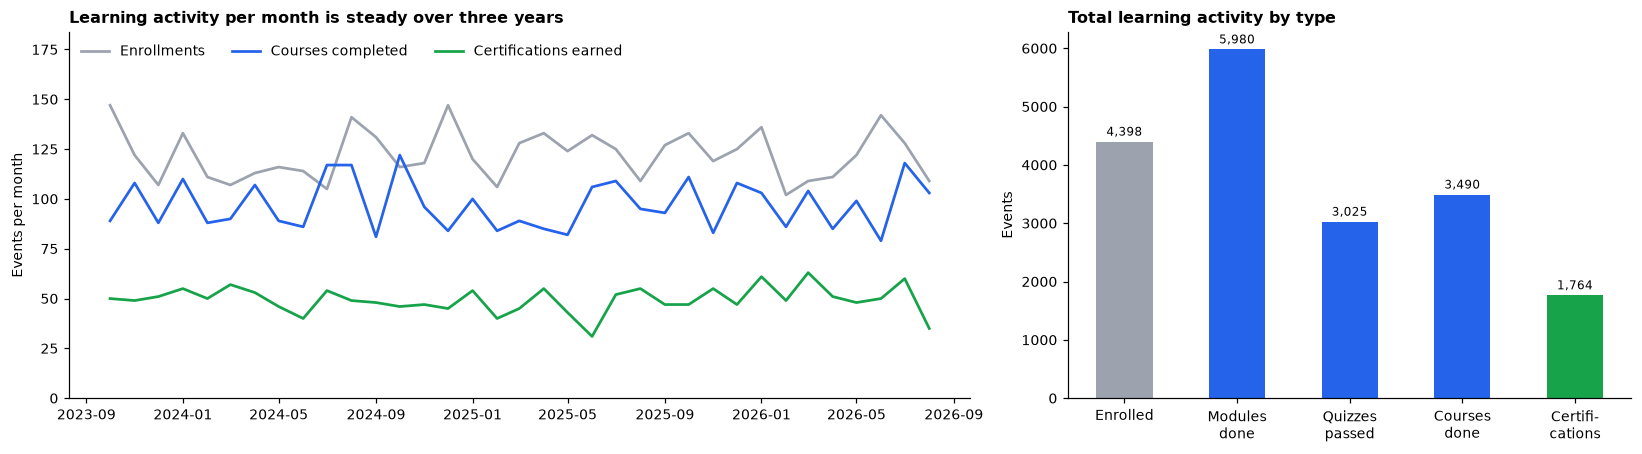

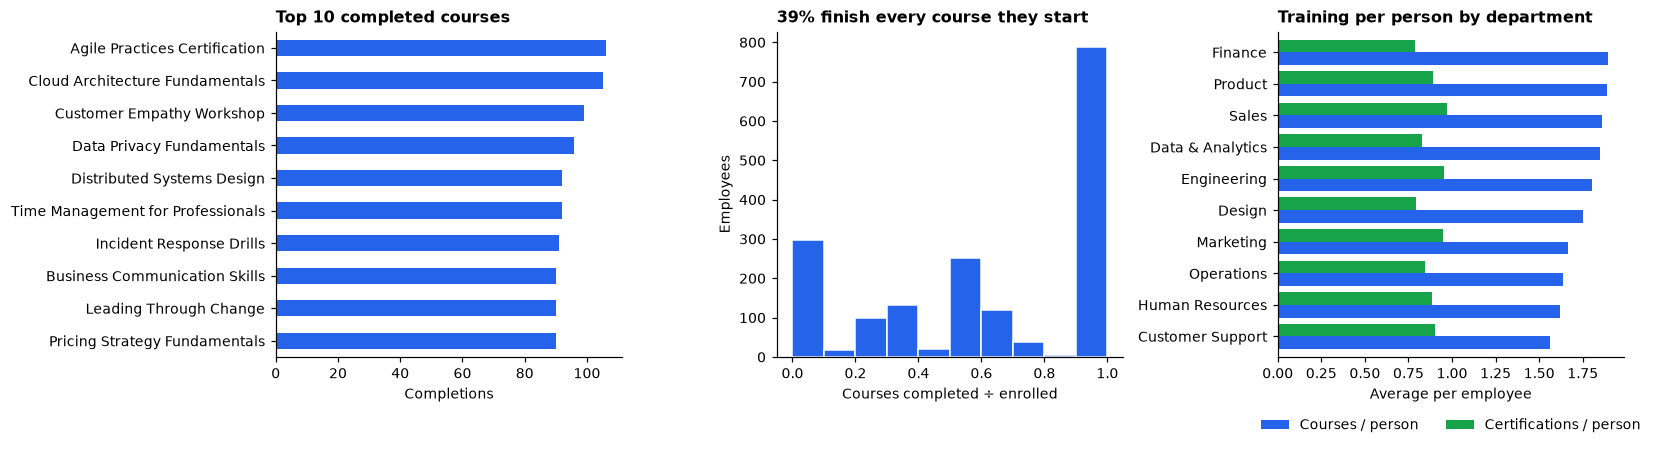

In [17]:
inactive = int(((risk["days_since_last_learning"] > 180) | risk["days_since_last_learning"].isna()).sum())
display(Markdown(f"### Answer: all **{(learning['total_events'] > 0).sum():,}** employees took part in training. They completed **{int(learning['course_completed_count'].sum()):,} courses** and "
                 f"earned **{int(learning['certification_earned_count'].sum()):,} certifications**; **{(learning['course_completed_count'] > 0).mean():.0%}** completed at least one course."))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.2), gridspec_kw={"width_ratios": [1.6, 1]})
by_type = (events[events["event_type"].isin(["enrollment", "course_completed", "certification_earned"])]
           .set_index("event_ts").groupby("event_type").resample("MS")["event_id"].count().unstack(0).iloc[1:-1])
for col, color, label in [("enrollment", GREY, "Enrollments"), ("course_completed", BLUE, "Courses completed"),
                          ("certification_earned", GREEN, "Certifications earned")]:
    axes[0].plot(by_type.index, by_type[col], color=color, label=label, linewidth=1.8)
axes[0].set(title="Learning activity per month is steady over three years", ylabel="Events per month",
            ylim=(0, by_type.values.max() * 1.25))
axes[0].legend(ncol=3, loc="upper left", frameon=False)

funnel = learning[["enrollment_count", "module_completed_count", "quiz_passed_count", "course_completed_count",
                   "certification_earned_count"]].sum()
funnel.index = ["Enrolled", "Modules\ndone", "Quizzes\npassed", "Courses\ndone", "Certifi-\ncations"]
funnel.plot.bar(ax=axes[1], color=[GREY, BLUE, BLUE, BLUE, GREEN], rot=0)
axes[1].set(title="Total learning activity by type", ylabel="Events")
label_bars(axes[1])
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
courses = top_counts(events.loc[events["event_type"] == "course_completed", "course_name"], 10)
courses.iloc[::-1].plot.barh(ax=axes[0], color=BLUE)
axes[0].set(title="Top 10 completed courses", xlabel="Completions", ylabel="")
learning["completion_rate"].dropna().plot.hist(ax=axes[1], bins=10, color=BLUE, edgecolor="white")
axes[1].set(title=f"{(learning['completion_rate'] >= 1).mean():.0%} finish every course they start",
            xlabel="Courses completed ÷ enrolled", ylabel="Employees")
dept_learn = learning.groupby("department")[["course_completed_count", "certification_earned_count"]].mean()
dept_learn.columns = ["Courses / person", "Certifications / person"]
dept_learn.sort_values("Courses / person").plot.barh(ax=axes[2], color=[BLUE, GREEN], width=0.8)
axes[2].set(title="Training per person by department", xlabel="Average per employee", ylabel="")
axes[2].legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2, frameon=False)
plt.tight_layout()
plt.show()

In [18]:
# Training completed by each employee (first 15 of 2,000 rows).
learning[["employee_id", "full_name", "department", "enrollment_count", "module_completed_count", "quiz_passed_count",
          "course_completed_count", "certification_earned_count", "completion_rate", "avg_quiz_score",
          "last_activity_date"]].sort_values("employee_id").head(15)

,employee_id,full_name,department,enrollment_count,module_completed_count,quiz_passed_count,course_completed_count,certification_earned_count,completion_rate,avg_quiz_score,last_activity_date
0,1,Heather Davis,Sales,2,1,3,2,1,1.000,65.5,2026-06-23
1,2,Kristie Heath,Sales,3,5,1,2,2,0.667,62.2,2026-07-16
2,3,Brandon Scott,Sales,4,6,3,3,1,0.750,62.1,2026-08-31
3,4,Gregory Williams,Sales,3,4,0,2,0,0.667,74.7,2026-02-25
4,5,Linda Murray,Sales,3,4,1,2,1,0.667,56.5,2026-07-24
5,6,Claudia Cole,Sales,2,1,0,0,0,0.000,99.0,2026-03-04
6,7,April Harrington,Sales,3,3,0,1,1,0.333,NaN,2026-07-16
7,8,Sherry Coleman,Sales,3,2,1,3,4,1.000,72.0,2026-05-28
8,9,Kyle Brown,Sales,5,2,1,0,2,0.000,49.3,2026-07-03
9,10,Tracie Gomez,Sales,0,3,0,2,1,NaN,64.4,2026-07-28


In [19]:
top_learner = learning.sort_values(["certification_earned_count", "course_completed_count", "employee_id"],
                                   ascending=[False, False, True]).iloc[0]
quiz_pass = learning["quiz_passed_count"].sum() / learning["quiz_attempted_count"].sum()
display(Markdown(f"""
**Key findings**
- **{(learning['course_completed_count'] > 0).mean():.0%}** completed at least one course and **{(learning['certification_earned_count'] > 0).mean():.0%}** earned a certification.
- Average completion rate **{learning['completion_rate'].mean():.1%}**; quiz pass rate **{quiz_pass:.0%}** (average score {learning['avg_quiz_score'].mean():.1f}).
- Activity is steady at about **{monthly.mean():,.0f} learning events per month**, with no seasonal drop.
- **{inactive}** employees have had no learning activity for more than 180 days. This also feeds the attrition-risk score (Q5).
- Most completed course: **{courses.index[0]}** ({courses.iloc[0]}). Top learner: **{top_learner['full_name']}** ({int(top_learner['certification_earned_count'])} certifications).
"""))


**Key findings**
- **83%** completed at least one course and **58%** earned a certification.
- Average completion rate **62.5%**; quiz pass rate **69%** (average score 66.9).
- Activity is steady at about **821 learning events per month**, with no seasonal drop.
- **317** employees have had no learning activity for more than 180 days. This also feeds the attrition-risk score (Q5).
- Most completed course: **Agile Practices Certification** (106). Top learner: **Donald Nichols** (6 certifications).


<a id="q5"></a>
---
# Q5. Which employees are at risk of attrition based on performance trends?

**How it is measured:** an **explainable** 0–100 score (`gold.attrition_risk`). Every point can be traced to a signal:

| Signal | Points |
|---|---:|
| HR attrition risk label High / Medium | 40 / 20 |
| Rating dropped by 2 / by 1 since last review | 25 / 15 |
| Latest rating ≤ 2 | 15 |
| No learning activity in 180 days | 10 |
| Tenure under 1 year | 10 |

Bands: **High ≥ 60**, **Medium ≥ 30**, otherwise Low. This is a transparent rule-based score, not a trained prediction model.

### Answer: **169 employees** are at **high** risk, including **57 high-potential employees**. Of the 230 employees whose rating fell, **62%** are already rated High risk by HR.

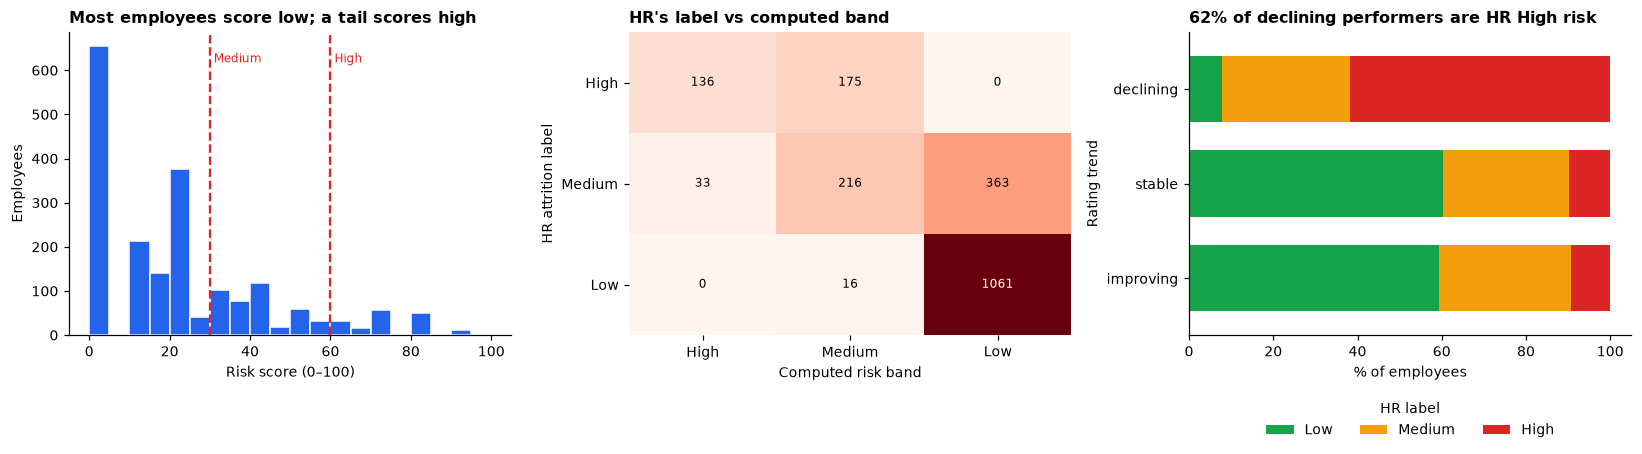

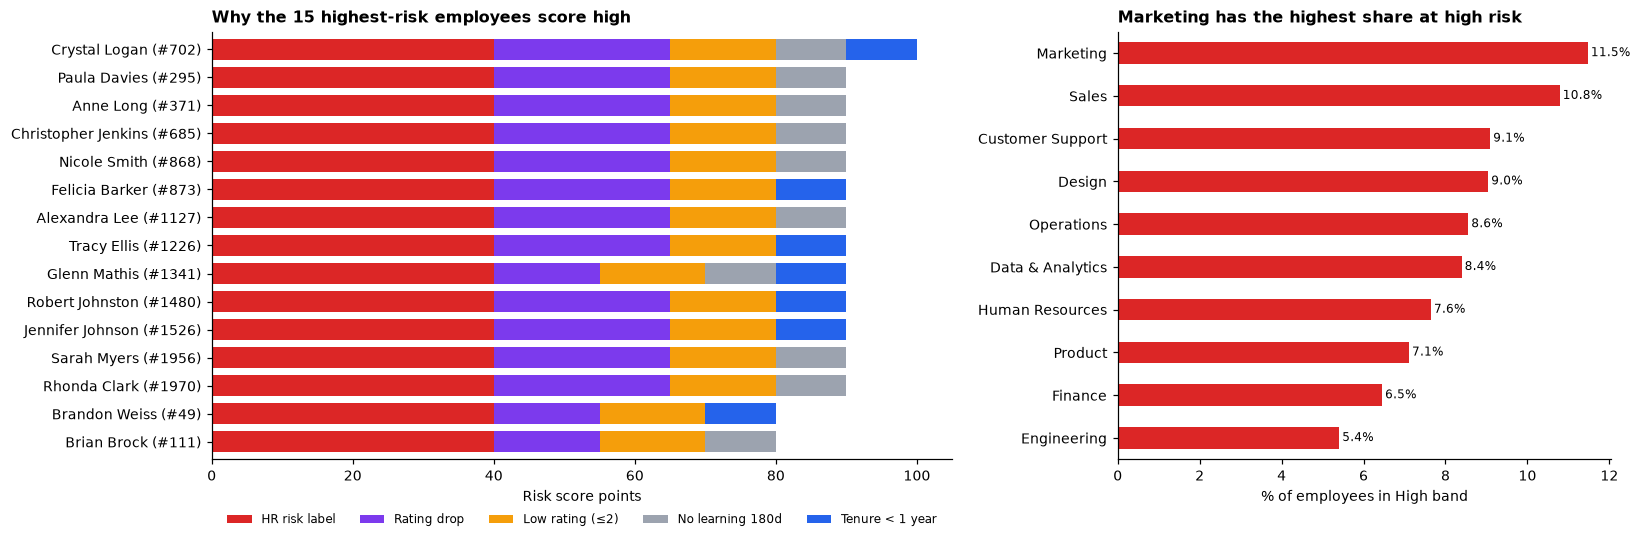

In [20]:
declining = risk[risk["rating_trend"] == "declining"]
agree = (declining["hr_attrition_risk"] == "High").mean()
display(Markdown(f"### Answer: **{bands['High']} employees** are at **high** risk, including **{len(hp_at_risk)} high-potential employees**. "
                 f"Of the {len(declining)} employees whose rating fell, **{agree:.0%}** are already rated High risk by HR."))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
risk["computed_risk_score"].plot.hist(ax=axes[0], bins=range(0, 105, 5), color=BLUE, edgecolor="white")
for cut, label in [(30, "Medium"), (60, "High")]:
    axes[0].axvline(cut, color=RED, linestyle="--")
    axes[0].text(cut + 1, axes[0].get_ylim()[1] * 0.9, label, color=RED, fontsize=8)
axes[0].set(title="Most employees score low; a tail scores high", xlabel="Risk score (0–100)", ylabel="Employees")

matrix = pd.crosstab(risk["hr_attrition_risk"], risk["risk_band"]).reindex(
    index=["High", "Medium", "Low"], columns=["High", "Medium", "Low"]).fillna(0)
heatmap(axes[1], matrix)
axes[1].set(title="HR's label vs computed band", xlabel="Computed risk band", ylabel="HR attrition label")

trend_risk = pd.crosstab(risk["rating_trend"], risk["hr_attrition_risk"], normalize="index").reindex(
    index=["improving", "stable", "declining"], columns=["Low", "Medium", "High"]) * 100
trend_risk.plot.barh(ax=axes[2], stacked=True, color=[GREEN, AMBER, RED], width=0.7)
axes[2].set(title=f"{agree:.0%} of declining performers are HR High risk", xlabel="% of employees", ylabel="Rating trend")
axes[2].legend(title="HR label", loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3, frameon=False)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1.5, 1]})
top15 = risk.sort_values(["computed_risk_score", "employee_id"], ascending=[False, True]).head(15)
parts = risk_components(top15)
parts.index = [f"{n} (#{i})" for n, i in zip(top15["full_name"], top15["employee_id"])]
parts.iloc[::-1].plot.barh(ax=axes[0], stacked=True, color=[RED, PURPLE, AMBER, GREY, BLUE], width=0.75)
axes[0].set(title="Why the 15 highest-risk employees score high", xlabel="Risk score points", xlim=(0, 105))
axes[0].legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.1), frameon=False, fontsize=8)
dept_risk = ((risk["risk_band"] == "High").groupby(risk["department"]).mean() * 100).sort_values()
dept_risk.plot.barh(ax=axes[1], color=RED)
axes[1].set(title=f"{dept_risk.index[-1]} has the highest share at high risk", xlabel="% of employees in High band", ylabel="")
label_bars(axes[1], "{:.1f}%")
plt.tight_layout()
plt.show()

In [21]:
# Priority list: high-potential employees in the High risk band.
print(f"{len(hp_at_risk)} high-potential employees at high risk (first 15 shown)")
hp_at_risk.sort_values(["computed_risk_score", "employee_id"], ascending=[False, True])[
    ["employee_id", "full_name", "department", "job_level", "latest_rating", "rating_delta",
     "days_since_last_learning", "tenure_years", "computed_risk_score"]].head(15)

57 high-potential employees at high risk (first 15 shown)


,employee_id,full_name,department,job_level,latest_rating,rating_delta,days_since_last_learning,tenure_years,computed_risk_score
294,295,Paula Davies,Product,Manager,1.0,-2.0,192,7.2,90
872,873,Felicia Barker,Customer Support,Manager,2.0,-2.0,84,0.8,90
1126,1127,Alexandra Lee,Operations,IC3,1.0,-2.0,198,6.4,90
1340,1341,Glenn Mathis,Human Resources,IC3,1.0,-1.0,196,0.3,90
1479,1480,Robert Johnston,Design,Director,1.0,-2.0,51,0.3,90
1525,1526,Jennifer Johnson,Sales,IC2,1.0,-2.0,49,0.3,90
48,49,Brandon Weiss,Sales,Senior Manager,1.0,-1.0,57,0.9,80
244,245,Karen Rosales,Customer Support,Manager,2.0,-2.0,135,3.8,80
360,361,Desiree Robertson,Data & Analytics,Director,1.0,-2.0,133,5.7,80
520,521,Charles Smith,Operations,IC1,1.0,-2.0,120,2.6,80


In [22]:
display(Markdown(f"""
**Key findings**
- **{bands['High']}** High, **{bands['Medium']}** Medium and **{bands['Low']:,}** Low risk employees.
- Performance trends and HR's judgement agree: **{agree:.0%}** of the {len(declining)} declining performers are HR High risk.
- The score adds information. **{int(matrix.loc['Medium', 'High'])}** employees HR rated only Medium reach the High band, because their ratings and engagement fell.
- **{len(hp_at_risk)} high-potential employees** are in the High band. They should get retention conversations first.
- **{dept_risk.index[-1]}** ({dept_risk.iloc[-1]:.1f}%) has the highest share at high risk; **{dept_risk.index[0]}** ({dept_risk.iloc[0]:.1f}%) the lowest.
"""))


**Key findings**
- **169** High, **407** Medium and **1,424** Low risk employees.
- Performance trends and HR's judgement agree: **62%** of the 230 declining performers are HR High risk.
- The score adds information. **33** employees HR rated only Medium reach the High band, because their ratings and engagement fell.
- **57 high-potential employees** are in the High band. They should get retention conversations first.
- **Marketing** (11.5%) has the highest share at high risk; **Engineering** (5.4%) the lowest.


<a id="q6"></a>
---
# Q6. How does employee performance correlate with team and project outcomes?

**How it is measured:** `gold.team_performance_outcomes` aggregates each team's latest ratings, skill gaps and projects. `gold.team_outcome_correlation` holds the Pearson correlation **r** over the teams that have projects.

### Answer: teams with higher performance ratings deliver projects **on time far more often**: **88%** of projects against **35%** (r = 0.54). The link to project quality scores is weaker (r = 0.24).

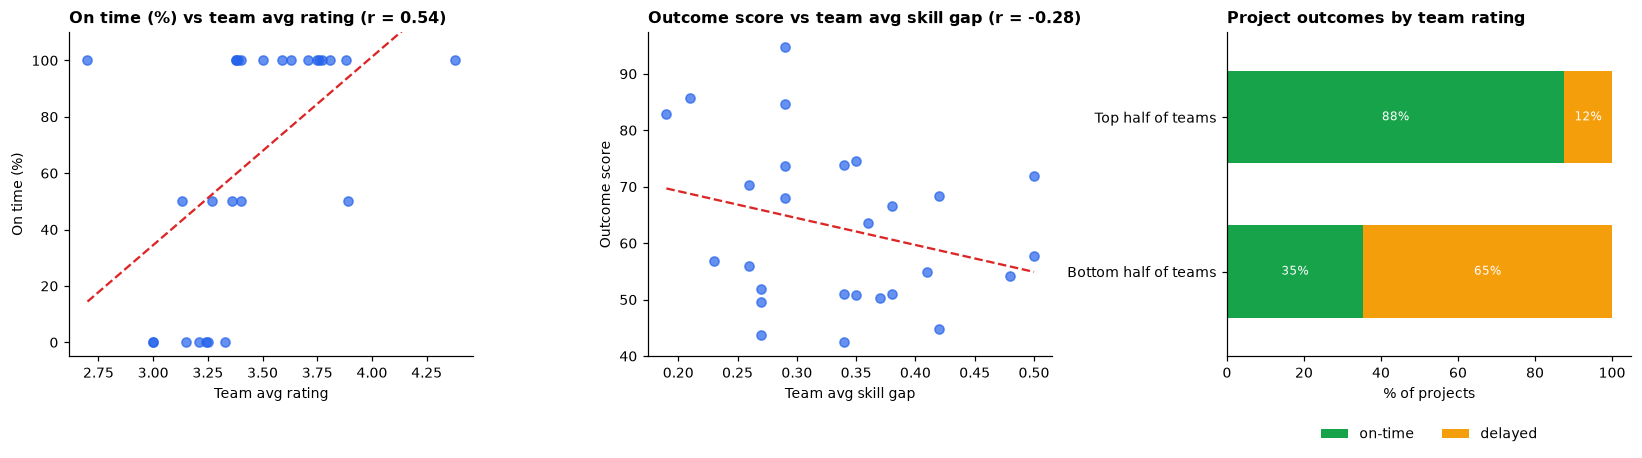

,metric_x,metric_y,n_teams,pearson_r,strength,direction
0,avg_rating_latest,avg_outcome_score,27,0.240,weak,positive
1,avg_rating_latest,on_time_pct,27,0.536,strong,positive
2,pct_high_performers,avg_outcome_score,27,0.158,weak,positive
3,pct_high_performers,on_time_pct,27,0.384,moderate,positive
4,avg_skill_gap,avg_outcome_score,27,-0.281,weak,negative
5,avg_skill_gap,on_time_pct,27,-0.225,weak,negative


In [23]:
r_score = corr.query("metric_x == 'avg_rating_latest' and metric_y == 'avg_outcome_score'")["pearson_r"].iloc[0]
median = with_projects["avg_rating_latest"].median()
tier = np.where(with_projects["avg_rating_latest"] >= median, "Top half of teams", "Bottom half of teams")
# Share of all projects (not an average of team percentages), so a 1-project team does not weigh as much as a 3-project team.
tiered_projects = projects.merge(with_projects.assign(tier=tier)[["team_id", "tier"]], on="team_id")
halves = tiered_projects.assign(on_time_pct=(tiered_projects["outcome_status"] == "on-time") * 100.0).groupby("tier").agg(
    on_time_pct=("on_time_pct", "mean"), avg_outcome_score=("outcome_score", "mean"), projects=("project_id", "count"),
    teams=("team_id", "nunique")).loc[["Top half of teams", "Bottom half of teams"]]
display(Markdown(f"### Answer: teams with higher performance ratings deliver projects **on time far more often**: "
                 f"**{halves.loc['Top half of teams', 'on_time_pct']:.0f}%** of projects against **{halves.loc['Bottom half of teams', 'on_time_pct']:.0f}%** "
                 f"(r = {r_on_time:.2f}). The link to project quality scores is weaker (r = {r_score:.2f})."))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))


def scatter(ax, x, y, xlabel, ylabel):
    ax.scatter(with_projects[x], with_projects[y], color=BLUE, alpha=0.7)
    slope, intercept = np.polyfit(with_projects[x], with_projects[y], 1)
    xs = np.linspace(with_projects[x].min(), with_projects[x].max(), 10)
    ax.plot(xs, slope * xs + intercept, color=RED, linestyle="--")
    r = corr.loc[(corr["metric_x"] == x) & (corr["metric_y"] == y), "pearson_r"].iloc[0]
    ax.set(title=f"{ylabel} vs {xlabel.lower()} (r = {r:.2f})", xlabel=xlabel, ylabel=ylabel)
    if y == "on_time_pct":
        ax.set_ylim(-5, 110)


scatter(axes[0], "avg_rating_latest", "on_time_pct", "Team avg rating", "On time (%)")
scatter(axes[1], "avg_skill_gap", "avg_outcome_score", "Team avg skill gap", "Outcome score")

status = (tiered_projects.pipe(lambda d: pd.crosstab(d["tier"], d["outcome_status"], normalize="index") * 100)
          .reindex(index=["Top half of teams", "Bottom half of teams"],
                   columns=["on-time", "delayed", "at-risk", "cancelled"]).fillna(0))
status_colors = dict(zip(["on-time", "delayed", "at-risk", "cancelled"], [GREEN, AMBER, RED, GREY]))
status = status.loc[:, status.sum() > 0]  # only statuses that occur
status.plot.barh(ax=axes[2], stacked=True, color=[status_colors[c] for c in status.columns], width=0.6)
for container in axes[2].containers:
    axes[2].bar_label(container, labels=[f"{v:.0f}%" if v >= 5 else "" for v in container.datavalues],
                      label_type="center", fontsize=8, color="white")
axes[2].invert_yaxis()
axes[2].set(title="Project outcomes by team rating", xlabel="% of projects", ylabel="")
axes[2].legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.18), frameon=False)
plt.tight_layout()
plt.show()

display(corr.assign(strength=pd.cut(corr["pearson_r"].abs(), [0, 0.3, 0.5, 1], labels=["weak", "moderate", "strong"]),
                    direction=np.where(corr["pearson_r"] > 0, "positive", "negative")).drop(columns=[c for c in ["_run_id"] if c in corr]))

In [24]:
display(Markdown(f"""
**Key findings**
- Higher-rated teams deliver on time more often (**r = {r_on_time:.2f}**, moderate). Projects of the top-half teams ({int(halves.loc['Top half of teams', 'teams'])} teams, {int(halves.loc['Top half of teams', 'projects'])} projects): **{halves.loc['Top half of teams', 'on_time_pct']:.0f}%** on time; bottom half ({int(halves.loc['Bottom half of teams', 'teams'])} teams, {int(halves.loc['Bottom half of teams', 'projects'])} projects): **{halves.loc['Bottom half of teams', 'on_time_pct']:.0f}%**. Project statuses overall: {", ".join(f"{k} {v}" for k, v in projects["outcome_status"].value_counts().items())}.
- The link to project quality scores is weaker (r = {r_score:.2f}). Average score {halves.loc['Top half of teams', 'avg_outcome_score']:.1f} against {halves.loc['Bottom half of teams', 'avg_outcome_score']:.1f}.
- Teams with larger skill gaps have somewhat worse outcomes (negative r), which supports closing gaps (Q2).
- **Caveat:** only **{int(with_projects['project_count'].sum())} projects across {len(with_projects)} teams** ({len(teams) - len(with_projects)} teams have none), mostly one per team. Treat this as a strong signal, not proof. Correlation is not causation.
"""))


**Key findings**
- Higher-rated teams deliver on time more often (**r = 0.54**, moderate). Projects of the top-half teams (14 teams, 16 projects): **88%** on time; bottom half (13 teams, 17 projects): **35%**. Project statuses overall: on-time 20, delayed 13.
- The link to project quality scores is weaker (r = 0.24). Average score 67.4 against 57.1.
- Teams with larger skill gaps have somewhat worse outcomes (negative r), which supports closing gaps (Q2).
- **Caveat:** only **33 projects across 27 teams** (73 teams have none), mostly one per team. Treat this as a strong signal, not proof. Correlation is not causation.


<a id="q7"></a>
---
# Q7. What is the distribution of skills across the organization?

**How it is measured:** `gold.skill_distribution` counts skill assessments by competency, department and proficiency level (1–5). "Below required" uses each role's required level.

### Answer: skills follow a **bell curve around level 3**, and **25%** of assessments are below the role's required level. The weakest skill is **Stakeholder Management** (35% below required).

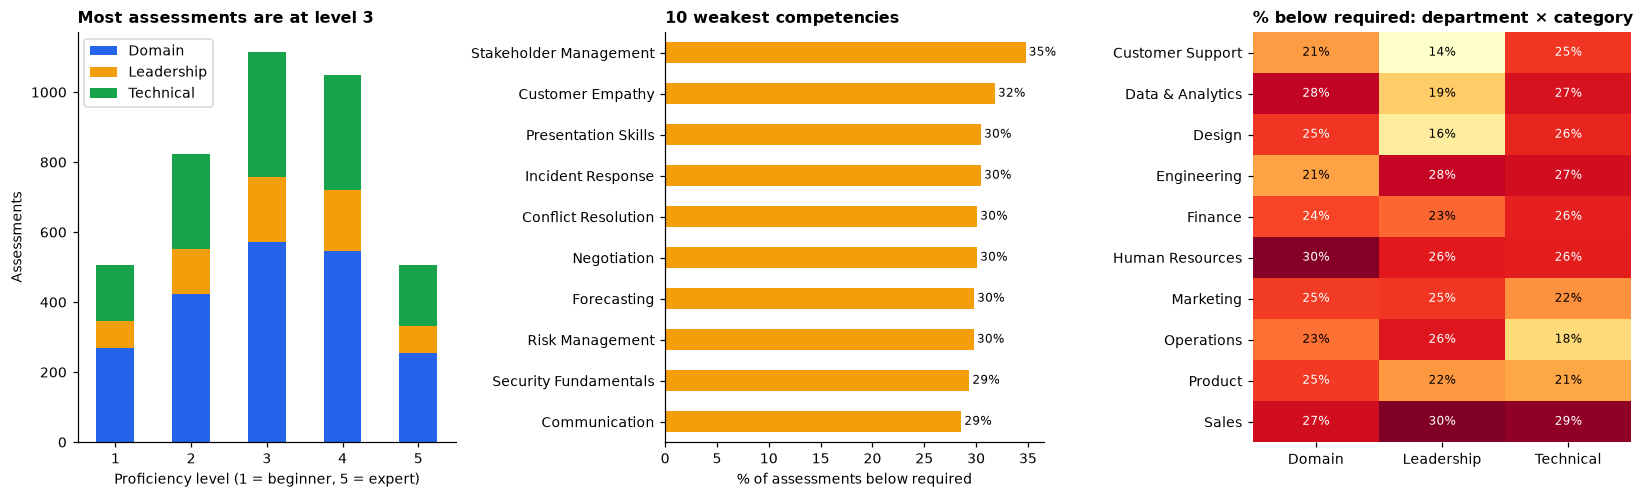

**Organization-wide proficiency distribution (% of assessments):**

proficiency_level,1,2,3,4,5
% of assessments,12.6,20.6,27.9,26.2,12.7


In [25]:
overall = skills.groupby("proficiency_level")["employee_count"].sum()
below = (gaps.assign(below=gaps["gap"] > 0).groupby("competency_name")["below"].mean() * 100).sort_values()
display(Markdown(f"### Answer: skills follow a **bell curve around level {overall.idxmax()}**, and **{(gaps['gap'] > 0).mean():.0%}** of assessments are below the role's "
                 f"required level. The weakest skill is **{below.index[-1]}** ({below.iloc[-1]:.0f}% below required)."))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
levels = skills.pivot_table(index="proficiency_level", columns="category", values="employee_count", aggfunc="sum")
levels.plot.bar(ax=axes[0], stacked=True, color=[BLUE, AMBER, GREEN], rot=0)
axes[0].set(title=f"Most assessments are at level {overall.idxmax()}", xlabel="Proficiency level (1 = beginner, 5 = expert)", ylabel="Assessments")
axes[0].legend(title=None)

below.tail(10).plot.barh(ax=axes[1], color=AMBER)
axes[1].set(title="10 weakest competencies", xlabel="% of assessments below required", ylabel="")
label_bars(axes[1], "{:.0f}%")

heat = gaps.assign(below=gaps["gap"] > 0).pivot_table(index="department", columns="category", values="below", aggfunc="mean") * 100
heatmap(axes[2], heat, fmt="{:.0f}%", cmap="YlOrRd")
axes[2].set_title("% below required: department × category")
plt.tight_layout()
plt.show()

display(Markdown("**Organization-wide proficiency distribution (% of assessments):**"))
display((overall / overall.sum() * 100).round(1).rename("% of assessments").to_frame().T)

In [26]:
dept_below = (gaps.assign(below=gaps["gap"] > 0).groupby("department")["below"].mean() * 100).sort_values()
cat_counts = skills.groupby("category")["competency_id"].nunique()
display(Markdown(f"""
**Key findings**
- **{int(overall.sum()):,}** assessments across **{skills['competency_id'].nunique()}** competencies ({", ".join(f"{k} {v}" for k, v in cat_counts.items())}).
- Bell-shaped: level **{overall.idxmax()}** is most common ({overall.max() / overall.sum():.0%}); only {overall.loc[5] / overall.sum():.0%} are expert (level 5).
- **{(gaps['gap'] > 0).mean():.0%}** of assessments are below the required level.
- Weakest: **{below.index[-1]}** ({below.iloc[-1]:.0f}%), **{below.index[-2]}** ({below.iloc[-2]:.0f}%), **{below.index[-3]}** ({below.iloc[-3]:.0f}%). Strongest: **{below.index[0]}** ({below.iloc[0]:.0f}%).
- **{dept_below.index[-1]}** has the most skills below required ({dept_below.iloc[-1]:.0f}%); **{dept_below.index[0]}** the fewest ({dept_below.iloc[0]:.0f}%).
"""))


**Key findings**
- **4,000** assessments across **40** competencies (Domain 21, Leadership 6, Technical 13).
- Bell-shaped: level **3** is most common (28%); only 13% are expert (level 5).
- **25%** of assessments are below the required level.
- Weakest: **Stakeholder Management** (35%), **Customer Empathy** (32%), **Presentation Skills** (30%). Strongest: **Vendor Management** (18%).
- **Sales** has the most skills below required (28%); **Customer Support** the fewest (21%).


<a id="explorer"></a>
---
# 3. Interactive explorer

Use the controls to filter the dashboard by **department** or open the profile of **any employee**. The controls work while the notebook runs in Jupyter. Below them is a static example of each view, so the report is still readable as a saved file.

In [27]:
def department_view(dept: str) -> None:
    """KPI cards and charts for one department ('All' for the whole company)."""
    pick = (lambda df: df) if dept == "All" else (lambda df: df[df["department"] == dept])
    r, g, p, l = pick(risk), pick(gaps), pick(promo), pick(learning)
    crit = g[g["gap_severity"] == "critical"]
    kpi_cards([
        ("Employees", f"{len(r):,}", dept, BLUE),
        ("Avg latest rating", f"{r['latest_rating'].mean():.2f}", f"company {risk['latest_rating'].mean():.2f}", BLUE),
        ("Declining", f"{(r['rating_trend'] == 'declining').sum()}", "rating fell", AMBER),
        ("Critical gaps", f"{crit['employee_id'].nunique()}", "employees", RED),
        ("Recommended", f"{int(p['is_recommended'].sum())}", f"of {len(p)} candidates", GREEN),
        ("High risk", f"{(r['risk_band'] == 'High').sum()}", f"{((r['risk_band'] == 'High') & (r['potential_rating'] == 'High')).sum()} high-potential", RED),
    ])
    fig, axes = plt.subplots(1, 3, figsize=(15, 3.4))
    r["latest_rating"].value_counts().reindex(range(1, 6)).fillna(0).plot.bar(ax=axes[0], color=BLUE, rot=0)
    axes[0].set(title="Latest ratings", xlabel="Rating", ylabel="Employees")
    b = r["risk_band"].value_counts().reindex(["High", "Medium", "Low"]).fillna(0)
    b.plot.bar(ax=axes[1], color=[RISK_COLORS[x] for x in b.index], rot=0)
    axes[1].set(title="Attrition risk bands", xlabel="", ylabel="Employees")
    top_counts(crit["competency_name"], 5).iloc[::-1].plot.barh(ax=axes[2], color=RED)
    axes[2].set(title="Top critical-gap competencies", xlabel="Employees", ylabel="")
    axes[2].xaxis.get_major_locator().set_params(integer=True)
    for ax in axes[:2]:
        label_bars(ax)
    plt.tight_layout()
    plt.show()


def employee_profile(employee_id: int) -> None:
    """One employee's ratings, risk breakdown, skills and learning."""
    row = risk[risk["employee_id"] == employee_id]
    if row.empty:
        display(Markdown(f"No employee with id {employee_id}."))
        return
    e = row.iloc[0]
    parts = risk_components(row).iloc[0]
    talent_row = talent[talent["employee_id"] == employee_id].iloc[0]
    candidate = promo[promo["employee_id"] == employee_id]
    display(Markdown(f"""
### {e['full_name']} (#{employee_id})
**{e['job_level']}**, {e['team_name']} ({e['department']}) · hired {e['hire_date']:%Y-%m-%d} ({e['tenure_years']:.1f} years)

| Performance | Talent review | Attrition risk |
|---|---|---|
| Latest rating **{e['latest_rating']:.0f}** ({e['rating_trend']}, change {e['rating_delta']:+.0f}) | Potential **{talent_row['potential_rating']}**, {talent_row['promotion_readiness']} | **{e['computed_risk_score']}/100 ({e['risk_band']})**; HR label {e['hr_attrition_risk']} |
| Average rating {e['avg_rating']:.2f} | Promotion: {"**recommended**" if (not candidate.empty and candidate.iloc[0]['is_recommended']) else ("candidate, not recommended" if not candidate.empty else "not a candidate")} | Score: {", ".join(f"{k} +{v:.0f}" for k, v in parts.items() if v)} |
"""))
    display(Markdown("**Review history**"))
    display(history.loc[history["employee_id"] == employee_id, ["review_period", "rating", "rating_delta", "manager_comment"]])
    display(Markdown("**Skills (largest gaps first)**"))
    display(gaps.loc[gaps["employee_id"] == employee_id, ["competency_name", "category", "proficiency_level", "required_level", "gap", "gap_severity"]]
            .sort_values("gap", ascending=False))
    display(Markdown("**Learning**"))
    display(learning.loc[learning["employee_id"] == employee_id, ["enrollment_count", "course_completed_count",
            "certification_earned_count", "completion_rate", "avg_quiz_score", "last_activity_date"]])

In [28]:
import ipywidgets as widgets

dept_picker = widgets.Dropdown(options=["All"] + sorted(risk["department"].unique()), description="Department")
employee_picker = widgets.Combobox(
    placeholder="Type a name or id", description="Employee", ensure_option=True,
    options=[f"{i} – {n}" for i, n in risk.sort_values("employee_id")[["employee_id", "full_name"]].itertuples(index=False)])
dept_out, emp_out = widgets.Output(), widgets.Output()


def on_dept(change=None):
    with dept_out:
        dept_out.clear_output(wait=True)
        department_view(dept_picker.value)


def on_employee(change=None):
    if employee_picker.value:
        with emp_out:
            emp_out.clear_output(wait=True)
            employee_profile(int(employee_picker.value.split(" – ")[0]))


dept_picker.observe(on_dept, names="value")
employee_picker.observe(on_employee, names="value")
on_dept()
widgets.VBox([widgets.HTML("<b>Department dashboard</b>"), dept_picker, dept_out,
              widgets.HTML("<b>Employee profile</b>"), employee_picker, emp_out])

**Static example: Marketing**, the department with the highest share of high-risk employees:

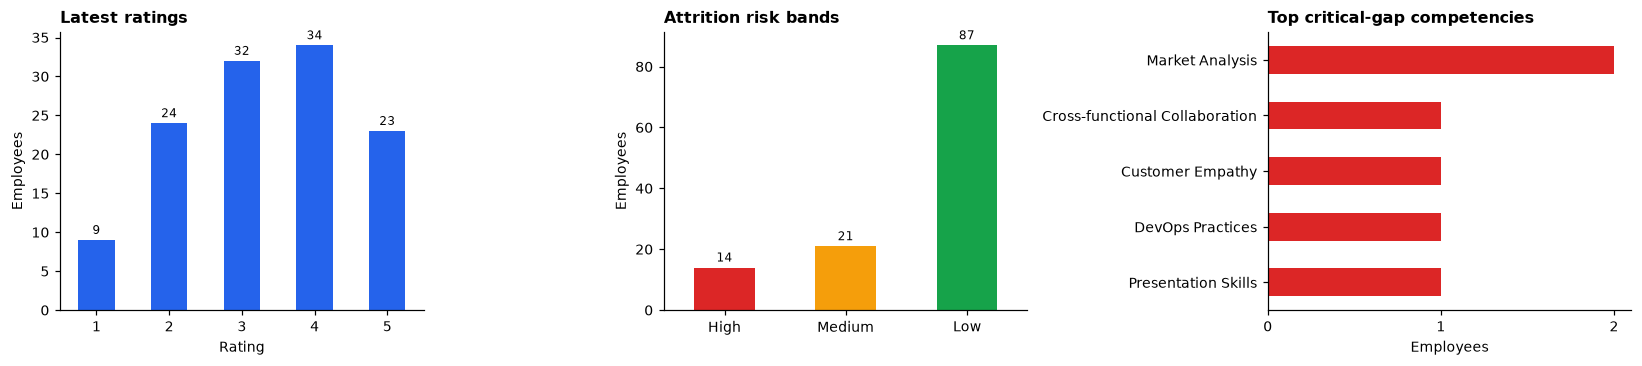

In [29]:
department_view("Marketing")

**Static example: employee #702**, the highest attrition-risk score:

In [30]:
employee_profile(702)


### Crystal Logan (#702)
**Director**, Team SlateBlue-36 (Marketing) · hired 2026-03-06 (0.6 years)

| Performance | Talent review | Attrition risk |
|---|---|---|
| Latest rating **1** (declining, change -2) | Potential **Medium**, 1-2 Years | **100/100 (High)**; HR label High |
| Average rating 2.00 | Promotion: not a candidate | Score: HR risk label +40, Rating drop +25, Low rating (≤2) +15, No learning 180d +10, Tenure < 1 year +10 |


**Review history**

,review_period,rating,rating_delta,manager_comment
1402,2024-H2,3.0,NaN,"Solid, consistent contributor this cycle."
1403,2025-H1,1.0,-2.0,Struggled to meet deadlines; follow-up plan re...


**Skills (largest gaps first)**

,competency_name,category,proficiency_level,required_level,gap,gap_severity
1402,Technical Writing,Domain,2,3,1,moderate
1403,Python,Technical,4,3,-1,none


**Learning**

,enrollment_count,course_completed_count,certification_earned_count,completion_rate,avg_quiz_score,last_activity_date
701,2,1,0,0.5,57.0,2025-11-21


<a id="summary"></a>
---
# 4. Summary and recommendations

In [31]:
display(Markdown(f"""
| # | Question | Answer |
|---|---|---|
| Q1 | Ratings and review history | Average {avg_by_period[first_p]:.2f} → {avg_by_period[latest_p]:.2f}; {int(trend['declining'])} employees declining |
| Q2 | Critical skill gaps | {critical['employee_id'].nunique()} employees; top: {top10.index[0]}, {top10.index[1]} |
| Q3 | Ready for promotion | {len(rec)} recommended of {len(promo)} HR candidates; {reasons['Blocked only by a critical gap']} blocked only by a skill gap |
| Q4 | Training completed | {int(learning['course_completed_count'].sum()):,} courses, {int(learning['certification_earned_count'].sum()):,} certifications; {inactive} inactive 180+ days |
| Q5 | Attrition risk | {bands['High']} High risk, including {len(hp_at_risk)} high-potential employees |
| Q6 | Performance vs outcomes | Top-half teams' projects {halves.loc['Top half of teams', 'on_time_pct']:.0f}% on time vs {halves.loc['Bottom half of teams', 'on_time_pct']:.0f}% (r = {r_on_time:.2f}) |
| Q7 | Skill distribution | Bell curve around level {overall.idxmax()}; {(gaps['gap'] > 0).mean():.0%} below required; weakest {below.index[-1]} |

### Recommended actions
1. **Retain:** hold retention conversations with the **{len(hp_at_risk)} high-potential employees** in the High risk band (Q5).
2. **Promote:** move forward with the **{len(rec)} recommended candidates**, starting with the **{len(flight)}** at High attrition risk (Q3).
3. **Develop:** run company-wide programmes for **{below.index[-1]}** and **{top10.index[0]}**, and give the **{reasons['Blocked only by a critical gap']}** near-ready candidates targeted training (Q2, Q3, Q7).
4. **Re-engage:** contact the **{inactive}** employees with no learning for 180+ days. Inactivity is a risk signal (Q4, Q5).
5. **Calibrate:** review whether the rating rise reflects real improvement or a change in how managers used the scale (Q1).
6. **Invest in team capability:** higher-rated, lower-gap teams deliver on time more often (Q6).
"""))


| # | Question | Answer |
|---|---|---|
| Q1 | Ratings and review history | Average 3.02 → 3.41; 230 employees declining |
| Q2 | Critical skill gaps | 317 employees; top: Strategic Thinking, Stakeholder Management |
| Q3 | Ready for promotion | 132 recommended of 357 HR candidates; 34 blocked only by a skill gap |
| Q4 | Training completed | 3,490 courses, 1,764 certifications; 317 inactive 180+ days |
| Q5 | Attrition risk | 169 High risk, including 57 high-potential employees |
| Q6 | Performance vs outcomes | Top-half teams' projects 88% on time vs 35% (r = 0.54) |
| Q7 | Skill distribution | Bell curve around level 3; 25% below required; weakest Stakeholder Management |

### Recommended actions
1. **Retain:** hold retention conversations with the **57 high-potential employees** in the High risk band (Q5).
2. **Promote:** move forward with the **132 recommended candidates**, starting with the **13** at High attrition risk (Q3).
3. **Develop:** run company-wide programmes for **Stakeholder Management** and **Strategic Thinking**, and give the **34** near-ready candidates targeted training (Q2, Q3, Q7).
4. **Re-engage:** contact the **317** employees with no learning for 180+ days. Inactivity is a risk signal (Q4, Q5).
5. **Calibrate:** review whether the rating rise reflects real improvement or a change in how managers used the scale (Q1).
6. **Invest in team capability:** higher-rated, lower-gap teams deliver on time more often (Q6).


### Assumptions and limitations
- **Two review periods only** (2024-H2, 2025-H1), so trends compare two points. They are not a long-term trajectory.
- **One talent-review cycle** (2025-H1). Potential and readiness are HR's judgement at that point.
- **The attrition score is a transparent rule**, not a statistical model. Its weights are business assumptions and can be tuned in `settings.py`.
- **Few projects** (33 across 27 teams), so the team-outcome correlations are indicative, not conclusive.
- **"Today"** for tenure and learning recency is the pipeline's `AS_OF_DATE` (shown in section 1).
- **Excluded data:** 143 malformed or invalid learning-log lines and 151 duplicates are in quarantine, not in these numbers (section 1).

<a id="sql"></a>
---
# Appendix: the same answers in SQL

Every chart above can be reproduced in pgAdmin from the published `gold` schema:

```sql
-- Q1 Ratings and review history
SELECT employee_id, full_name, review_period, rating, rating_delta, manager_comment
FROM gold.employee_performance_history ORDER BY employee_id, review_period;

-- Q2 Critical skill gaps
SELECT employee_id, full_name, department, competency_name, proficiency_level, required_level, gap
FROM gold.employee_skill_gaps WHERE gap_severity = 'critical' ORDER BY department, employee_id;

-- Q3 Recommended for promotion
SELECT employee_id, full_name, department, job_level, latest_rating, rating_trend, attrition_risk
FROM gold.promotion_candidates WHERE is_recommended ORDER BY latest_rating DESC, avg_rating DESC;

-- Q4 Training completed per employee
SELECT employee_id, full_name, course_completed_count, certification_earned_count, completion_rate
FROM gold.employee_learning_summary ORDER BY employee_id;

-- Q5 Highest attrition risk
SELECT employee_id, full_name, hr_attrition_risk, latest_rating, rating_delta, computed_risk_score, risk_band
FROM gold.attrition_risk ORDER BY computed_risk_score DESC;

-- Q6 Team performance vs project outcomes
SELECT * FROM gold.team_outcome_correlation;

-- Q7 Skill distribution
SELECT competency_name, category, department, proficiency_level, employee_count, pct_below_required
FROM gold.skill_distribution ORDER BY competency_name, department, proficiency_level;

-- Data quality: rejected learning-log lines by rule
SELECT _rule_id, COUNT(*) FROM quarantine.learning_activity GROUP BY _rule_id ORDER BY 2 DESC;
```

In [32]:
if conn is not None:
    conn.close()